# Background estimate of the 2μ2e and 4μ search regions

This notebook assembles the ABCD background estimate of the two search regions from the 2018 data
and states how well the method's assumption is tested. Throughout, a lepton jet (LJ) is a cluster
of two muons (a muon LJ) or of electrons and photons (an egamma LJ); the search regions pair a
muon LJ with an egamma LJ (2μ2e) or with a second muon LJ (4μ).

**The method in one paragraph.** Every event has two objects: the leading muon LJ (object 0) and
the second object (object 1: the egamma LJ in 2μ2e, the subleading muon LJ in 4μ). Each object is
*prompt* or *displaced* — a muon LJ is displaced when the maximum pixel-hit count over its muons
is ≤ 2, an egamma LJ when its minimum lost-hit count is ≥ 1 (photon-only LJs carry the sentinel
999 and are displaced by construction) — which gives four planes **PP, PD, DP, DD**, first letter
the muon LJ. The signal lives in DD. Event cuts everywhere: LJ-pair mass M ≥ 150 GeV (the high-mass
window; M < 150 GeV is the open low-mass window) and the second object isolated, iso1 < 0.5. Inside
each plane the ABCD grid uses two variables of the leading muon LJ, its isolation iso0 and its
azimuthal separation from the other object $|\Delta\phi|$:

| | iso0 < 0.25 | iso0 ≥ 0.25 |
|---|---|---|
| $|\Delta\phi| \ge 2.4$ | **A** | B |
| $|\Delta\phi| < 2.4$ | C | D |

The sidebands start at A's own edges: there is no buffer band between A and B or between A and C.
If iso0 and $|\Delta\phi|$ are independent for the background, A = B C/D; the measure of that is
κ = A D/(B C), measurable wherever A is open. A configuration label such as
`dphi 2.4/2.4 x iso0 0.25/0.25, iso1<0.5, M>=150` reads: the $|\Delta\phi|$ axis passes at ≥ 2.4
and fails below 2.4, the object-0 isolation passes below 0.25 and fails at ≥ 0.25, object 1 is
isolated below 0.5, and the LJ-pair mass is at least 150 GeV. `PD:dsa1+` and the like split a plane
by a stored variable (`mu*` pixel hits of object 0, `dsa*` its DSA-muon count, `e`/`g` the egamma
class, in 4μ `sub*` and `subdsa*` for object 1).

**The strategy.** The background in A of the DD plane is estimated four ways and the four are
compared: directly, as B C/D from DD's own sidebands, which assumes independence and nothing
else; and by borrowing a ratio from the PD plane (muon LJ prompt, egamma LJ displaced), B × (A/B),
C × (A/C) and D × (A/D), each ratio taken per class of the muon LJ (with or without a
displaced-standalone, DSA, muon) and summed, because the two classes have ratios a factor two
apart and the search plane's sidebands hold a far larger DSA share than PD. The independence
assumption is tested where A is open: in PP and PD above 150 GeV (large statistics, different
background mix), in DP above 150 GeV (the direct test of the muon-displacement step, small
statistics) and in DD itself below 150 GeV (the search plane's own correlation, coarse). The
systematic uncertainty of the estimate is the non-closure seen in those tests plus the spread
between the routes. The headline numbers are integrated over M ≥ 150 GeV, the one-bin search
region of the analysis; the windows 150–300 GeV and M ≥ 300 GeV (where the 500–1000 GeV signal
points sit) are carried alongside, because κ falls between the two windows in both planes. 4μ has too few
events in its DD sidebands for any ABCD and gets a count-limited estimate instead (section 5).

**What changed since the previous version of this notebook.** The earlier version kept a buffer
band between A and its sidebands (B at iso0 ≥ 0.5, C and D at $|\Delta\phi| < 2.0$), cut the muon
LJ's mass below 75 GeV, and used a proxy-muon region with a b-tagged jet as a further validation
region. The buffers are gone: the $|\Delta\phi|$ buffer was most of PP's non-closure (0.84 → 0.97
without it), the isolation buffer part of PD's (1.25 → 1.20), the signal in the two bands is
0.3–0.9% and 1.1–2.8% of the search-region yield, and the configuration scan of section 4 shows
that what remains is in the planes: PD stays 11–27% above one for every unbuffered boundary, and
PP closes at the search region's $|\Delta\phi|$ edge of 2.4 but not at 2.0 or 2.2. The mass cut is gone because it removed 7 of 1343 events in A of PD and
moved no ratio beyond its last digit — the Z → μμ muon LJ it targeted hardly occurs. The proxy
region is gone because its lone muon is not the search channel's object (its isolation pass/fail
ratio among back-to-back events was 6–23 against about one for a muon LJ) and its one subsample
with the search plane's ratios held 36 events; the b-tag requirement entered only through it. The hidden box is now the search
region itself.

**Blinding.** Data cubes are loaded only through `transfer_lib.summed_cubes`, which hides region
A — iso0 < 0.25, iso1 < 0.5, $|\Delta\phi| \ge 2.4$, M ≥ 150 GeV — of the DD plane in both
channels and, in 4μ, of the DP and PD planes as well: those two corners hold a quarter to a half
of the 4μ signal's search-region yield (section 5) against a background of tens of events, so they
are search regions in all but name, while their sidebands hold about 1% of that yield and are
open. A projection touching a hidden cell prints as "blind" or NaN. Signal and simulation cubes
are never hidden; signal shares of every region read from are tabulated.

**Inputs and normalisation.** The 2018 DoubleMuon data (59.83 fb⁻¹) after the certified
luminosity sections of `Cert_314472-325175_13TeV_Legacy2018_Collisions18_JSON`, the skimmed
LLPNanoAOD background samples of the shared `Backgrounds/2018_v2/Skims` area (Drell–Yan, QCD, top,
diboson) and the v10 signal samples, processed with the campaign code under `campaign/` (Dongyub
Lee's framework copy with a raw-event pre-filter added) into the eight-dimensional histograms
`abcd8d_<channel>`: the six axes of his `ABCD_6D_inclusive_eHEM_skimv1` campaign (the two
isolations, the two displacement variables, $|\Delta\phi|$, the LJ-pair mass) plus the leading muon
LJ's own mass and its DSA-muon count (in 4μ, the subleading muon LJ's DSA count as well).
Simulated events carry the generator weight and the HEM15/16 treatment of the `_eHEM` channels
(data events of runs ≥ 319077 with a jet or electron in the HEM15/16 region are removed; simulated
events with such an object are weighted by the unaffected luminosity fraction, 0.351). Each sample
is normalised to luminosity × cross section (`cross_sections.yaml`) by its summed generator weight
before the skim; the Condor chunks, each scaled with its own sum of weights, are merged as
Σ H_j S_j / Σ S_j (`merge_abcd8d.py`). No pileup reweighting, L1-prefiring weight or lepton scale
factor is applied: these are corrections of a few per cent to simulated yields, and simulation
enters this notebook only through composition tables and the signal-contamination estimates, never
the data-driven estimates themselves.

**Uncertainties.** 68.27% Clopper–Pearson intervals for ratios of disjoint counts, relative errors
added in quadrature for ratios of ratios and for sums over classes, the 68% upper limit of 1.84
events times the factor for a count of zero, $N_{\text{eff}}$ = (Σw)²/Σw² for simulated yields; a
"±" is printed where the two sides of an interval agree within 5%, otherwise "−m +p".

**One known difference to the 6D histograms.** The isolation axis of the 8D histograms has no
underflow bin, and an LJ's isolation can be slightly negative (the matched jet's energy fractions
can sum to more than one). The data and the QCD, top and diboson samples were filled with the
isolation clipped at zero; the Drell–Yan and signal samples were filled before that clip, so they
lack those events, which all lie in the isolation-pass regions. Section 1 measures the effect
(−9 of 130 simulated Drell–Yan events in A of PP).

In [1]:
import dataclasses
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import abcd6d_io as io
import transfer_lib as tl
import transfer_plots as tp
import plane_search_lib as ps
import plane_search_plots as pp
import estimate_lib as el

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 200)
tp.set_style()

BASE6D = tl.local_dir()
BASE = os.environ.get("ABCD8D_LOCAL", "/uscms_data/d3/murtazas/abcd8d_local")
print("6D inputs:", BASE6D)
print("8D inputs:", BASE)
data6 = tl.summed_cubes(BASE6D, "data")
data = tl.summed_cubes(BASE, "data", prefix="abcd8d")
print("hidden box:", io.blind_signature(prefix="abcd8d"))
for name, cubes in (("6D", data6), ("8D", data)):
    for t, c in cubes.items():
        print(f"{name} {t}: {c.sumw.shape}, {int(np.isnan(c.sumw).sum())} hidden cells, {np.nansum(c.sumw):.0f} open events")
d2, d4 = data["2mu2e"], data["4mu"]
NOMINAL = ps.Config(fail0=0.25, dphi_fail=2.4)             # no buffer between A and its sidebands
BUFFERED = ps.Config()                                      # the previous version's boundaries, for comparison
LOW = dataclasses.replace(NOMINAL, mass=(None, 150.0))
WINDOWS = [("M >= 150", NOMINAL),
           ("150-300", dataclasses.replace(NOMINAL, mass=(150.0, 300.0))),
           ("M >= 300", dataclasses.replace(NOMINAL, mass=(300.0, None)))]
PLANES = ("PP", "DP", "PD", "DD")
SIGNAL_POINTS = {"2mu2e": ["2Mu2E_200GeV_0p25GeV_1p0mm", "2Mu2E_500GeV_0p25GeV_0p4mm", "2Mu2E_800GeV_0p25GeV_0p25mm",
                           "2Mu2E_1000GeV_0p25GeV_0p2mm", "2Mu2E_800GeV_1p2GeV_1p2mm", "2Mu2E_1000GeV_1p2GeV_0p96mm",
                           "2Mu2E_800GeV_0p25GeV_1p2mm"],
                 "4mu": ["4Mu_200GeV_0p25GeV_1p0mm", "4Mu_500GeV_0p25GeV_0p4mm", "4Mu_800GeV_0p25GeV_0p25mm",
                         "4Mu_1000GeV_0p25GeV_0p2mm", "4Mu_800GeV_1p2GeV_1p2mm", "4Mu_1000GeV_1p2GeV_0p96mm",
                         "4Mu_800GeV_0p25GeV_1p2mm"]}
print("nominal configuration:", NOMINAL.label())
print("previous boundaries:  ", BUFFERED.label())

6D inputs: /uscms_data/d3/murtazas/abcd6d_local
8D inputs: /uscms_data/d3/murtazas/abcd8d_local


hidden box: iso0<0.25 iso1<0.5 mass>=150 dphi>=2.4 planes=[('2mu2e', ('displaced', 'displaced')), ('4mu', ('displaced', 'displaced')), ('4mu', ('displaced', 'prompt')), ('4mu', ('prompt', 'displaced'))]
6D 2mu2e: (14, 14, 14, 12, 16, 13), 174960 hidden cells, 23515 open events
6D 4mu: (14, 14, 14, 14, 16, 13), 419904 hidden cells, 9247 open events
8D 2mu2e: (12, 12, 6, 4, 10, 10, 8, 3), 241920 hidden cells, 23495 open events
8D 4mu: (12, 12, 6, 6, 10, 10, 5, 3, 3), 1360800 hidden cells, 9234 open events
nominal configuration: dphi 2.4/2.4 x iso0 0.25/0.25, iso1<0.5, M>=150
previous boundaries:   dphi 2.4/2 x iso0 0.25/0.5, iso1<0.5, M>=150


## 1. The histograms against the earlier campaign, and what the merge found

The 8D data cubes projected onto the 6D regions must reproduce the 6D counts exactly (same
events, same campaign skims, the clipped isolation lands in the first bin of the pass region
either way). The Drell–Yan sample was filled before the clip: its differences are the events it
lost. The comparison uses the previous boundaries, whose sidebands exist in both sets of cubes.

They do, to the event, in every 4μ region and in the pass regions of 2μ2e; the 2μ2e fail regions
lose a few events (B of PP 1021 → 1016, B and D of PD 886 → 885 and 163 → 162), and the open
totals 20 of 23,515 events in 2μ2e and 13 of 9,247 in 4μ. The known differences between the two
campaigns are the raw-event pre-filter of the new code, built to leave every channel's yield
unchanged, and the chunks the merge did not find (the manifest summary below: one data chunk of
12,771, and in the simulation 7 of 540 Drell–Yan chunks, 1 of 309 QCD chunks and one or two chunks
of three signal points, among them 2Mu2E_800GeV_0p25GeV_0p25mm with 3 of 4 — a loss of statistics,
not of normalisation, since every simulated chunk is scaled by its own sum of generator weights);
neither is shown here to account for the 20 events, and the pixel-hit axis of the new histograms,
which has no overflow bin, is not the cause (no muon LJ of the 6D cubes has 12 or more pixel hits).
The loss is 0.1%, sits in the regions with a non-isolated muon LJ, and is unexplained at that
level; it moves no ratio by more than 0.6% and nothing below depends on it. The Drell–Yan
differences are what the table says they are: −9 of 130 simulated events in A of PP from the
negative-isolation events the first code version did not clip, at most +3% elsewhere.

In [2]:
print("data, previous boundaries (planes PP, DP, PD, DD; the hidden regions stay hidden in both)")
for t in tl.TOPOLOGIES:
    print(t)
    display(el.consistency_table(data6[t], data[t], BUFFERED))
groups6 = tl.group_cubes(BASE6D, "bkg")
g2 = tl.group_cubes(BASE, "bkg", prefix="abcd8d", topologies=("2mu2e",))     # one topology at a time: a 4mu cube is 0.4 GB
print("process groups, 6D:", sorted(groups6), " 8D:", sorted(g2))
print("Drell-Yan, 2mu2e, all masses: 6D against 8D (the 8D cube lacks the negative-isolation events)")
display(el.consistency_table(groups6["DY"]["2mu2e"], g2["DY"]["2mu2e"], dataclasses.replace(BUFFERED, mass=(None, None))))
del groups6, data6
print("merge manifest: samples whose merged chunks fall short of the job list")
lines = open(os.path.join(BASE, "MANIFEST.txt")).read().splitlines()
short = []
for line in lines:
    m = re.match(r"(\S+) (\S+) chunks=(\d+)/(\d+)", line)
    if m and m.group(3) != m.group(4):
        short.append(f"{m.group(1)} {m.group(2)} {m.group(3)}/{m.group(4)}")
print(f"  {len(lines)} samples; incomplete: {', '.join(short) if short else 'none'}")

data, previous boundaries (planes PP, DP, PD, DD; the hidden regions stay hidden in both)
2mu2e


,plane,A 6D,A 8D,A diff,B 6D,B 8D,B diff,C 6D,C 8D,C diff,D 6D,D 8D,D diff
0,PP,797,797,+0,1021,1016,-5,121,121,+0,130,130,+0
1,DP,44,44,+0,54,54,+0,5,5,+0,7,7,+0
2,PD,1343,1343,+0,886,885,-1,196,196,+0,163,162,-1
3,DD,blind,blind,blind,50,50,+0,11,11,+0,14,14,+0


4mu


,plane,A 6D,A 8D,A diff,B 6D,B 8D,B diff,C 6D,C 8D,C diff,D 6D,D 8D,D diff
0,PP,264,264,+0,198,198,+0,23,23,+0,28,28,+0
1,DP,blind,blind,blind,24,24,+0,4,4,+0,1,1,+0
2,PD,blind,blind,blind,14,14,+0,7,7,+0,8,8,+0
3,DD,blind,blind,blind,1,1,+0,0,0,+0,0,0,+0


process groups, 6D: ['DY', 'QCD', 'diboson', 'ttbar']  8D: ['DY', 'QCD', 'diboson', 'ttbar']
Drell-Yan, 2mu2e, all masses: 6D against 8D (the 8D cube lacks the negative-isolation events)


,plane,A 6D,A 8D,A diff,B 6D,B 8D,B diff,C 6D,C 8D,C diff,D 6D,D 8D,D diff
0,PP,130.5 ± 33.8,121.2 ± 32.4,-9,9.7 ± 5.6,9.9 ± 5.7,+0,45.0 ± 16.3,45.4 ± 16.4,+0,6.5 ± 4.6,6.6 ± 4.7,+0
1,DP,3.2 ± 3.2,3.3 ± 3.3,+0,6.5 ± 4.6,6.6 ± 4.7,+0,0,0,+0,6.5 ± 4.6,6.6 ± 4.7,+0
2,PD,198.2 ± 38.5,199.1 ± 38.5,+1,3.2 ± 3.2,3.3 ± 3.3,+0,187.0 ± 31.1,188.7 ± 31.3,+2,3.2 ± 3.2,3.3 ± 3.3,+0
3,DD,3.2 ± 3.2,3.3 ± 3.3,+0,0,0,+0,3.2 ± 3.2,3.3 ± 3.3,+0,0,0,+0


merge manifest: samples whose merged chunks fall short of the job list
  266 samples; incomplete: bkg_rest QCD_Pt1000 308/309, data DoubleMuon_2018A_1 99/100, dy DYJetsToLL_M50 533/540, signal 2Mu2E_800GeV_0p25GeV_0p25mm 3/4, signal 4Mu_1000GeV_5p0GeV_0p04mm 4/6, signal 4Mu_500GeV_1p2GeV_1p9mm 6/7


## 2. 2μ2e: does the method's assumption hold where it can be tested?

### 2.1 The planes with A open

κ of every 2μ2e plane whose A is open, over the whole high-mass window and in its two parts, then
by DSA class of the muon LJ, then against the LJ-pair mass bin. The figure draws κ, A/B, B/D and
C/D of the two large planes against the mass. The first table repeats the measurement with the previous
boundaries so the effect of the buffers is visible.

Without the buffers **PP closes, 0.97 ± 0.10** (797/1545/202/379 events in A/B/C/D), and **PD does
not quite, 1.20 ± 0.10** (1343/1401/347/433), two standard deviations above one. DP, the plane with the displaced muon LJ and a prompt egamma LJ, gives 1.02 −0.41 +0.48 on
44/75/15/26 events, consistent with both. The previous boundaries gave PP 0.84 ± 0.12 and PD
1.25 ± 0.15: the $|\Delta\phi|$ buffer, which removed the 2.0–2.4 band from C and D, is what pulled
PP down (dropping it alone moves PP to 0.99 and leaves PD at 1.26), and the isolation buffer, which
removed the 0.25–0.5 band from B and D, is what pushed PD up (dropping it alone moves PD to 1.16
and PP to 0.78). PD's residual 20% is a property of the plane, not of a class: the PF-only muon
LJs give 1.24 ± 0.11 and the DSA-containing ones 0.73 −0.17 +0.19 (PP: 1.02 ± 0.11 and
0.59 −0.18 +0.20), so the two classes miss in opposite directions and a veto on the DSA class
would not repair it.

κ falls between the two windows, in both planes and by about two standard deviations each:
150–300 GeV gives PP 1.08 ± 0.13 and PD 1.31 ± 0.12, and M ≥ 300 GeV, where the 500–1000 GeV
signal points sit, PP 0.67 ± 0.15 and PD 0.87 ± 0.17, below one by 2.2 and 0.8 standard deviations.
Against a flat κ the five mass bins give χ² = 3.9 for 4 degrees of freedom in each plane, so the
data do not establish a mass dependence; the two windows differ enough that the per-window numbers
are carried. The integrated values are dominated by 150–300 GeV (1068 of PD's 1343 A events), so "closes integrated" is mostly "closes at
150–300 GeV". With the previous boundaries PP fell to 0.30 above 300 GeV while PD stayed at
1.05 ± 0.30 — the two planes did not share a trend; now they do, and it is mild.

the planes with A open, nominal boundaries, then the previous boundaries


,validation region,plane,A observed,B C/D,kappa,kappa - 1 [%],precision [%],verdict
0,"M >= 150, PP",PP,797,823.5 ± 74.7,0.97 ± 0.10,-3 (-10/+10),10,closes (target 15%)
1,"M >= 150, PD",PD,1343,1122.7 ± 86.3,1.20 ± 0.10,+20 (-10/+10),8,fails (target 15%)
2,"M >= 150, DP",DP,44,43.3 ± 14.9,1.02 -0.41 +0.48,+2 (-41/+48),47,imprecise (target 15%)
3,"150-300, PP",PP,598,551.8 ± 56.9,1.08 ± 0.13,+8 (-12/+13),12,closes (target 15%)
4,"150-300, PD",PD,1068,817.9 ± 70.4,1.31 ± 0.12,+31 (-12/+12),9,fails (target 15%)
5,"150-300, DP",DP,29,33.2 ± 13.4,0.87 -0.44 +0.50,-13 (-44/+50),57,imprecise (target 15%)
6,"M >= 300, PP",PP,199,295.1 ± 57.0,0.67 -0.15 +0.15,-33 (-15/+15),23,imprecise (target 15%)
7,"M >= 300, PD",PD,275,316.4 ± 54.4,0.87 ± 0.17,-13 (-17/+17),20,imprecise (target 15%)
8,"M >= 300, DP",DP,15,9.3 ± 6.5,1.61 -1.28 +2.30,+61 (-128/+230),143,imprecise (target 15%)


,validation region,plane,A observed,B C/D,kappa,kappa - 1 [%],precision [%],verdict
0,"M >= 150 (previous boundaries), PP",PP,797,945.7 ± 123.1,0.84 ± 0.12,-16 (-12/+12),14,fails (target 15%)
1,"M >= 150 (previous boundaries), PD",PD,1343,1070.7 ± 119.3,1.25 ± 0.15,+25 (-15/+15),12,fails (target 15%)
2,"150-300 (previous boundaries), PP",PP,598,538.0 ± 79.0,1.11 ± 0.18,+11 (-18/+18),16,imprecise (target 15%)
3,"150-300 (previous boundaries), PD",PD,1068,800.0 ± 99.8,1.33 ± 0.18,+34 (-18/+18),14,fails (target 15%)
4,"M >= 300 (previous boundaries), PP",PP,199,657.9 ± 203.8,0.30 -0.12 +0.10,-70 (-12/+10),39,imprecise (target 15%)
5,"M >= 300 (previous boundaries), PD",PD,275,261.8 ± 65.3,1.05 ± 0.30,+5 (-30/+30),29,imprecise (target 15%)


one buffer at a time, M >= 150 GeV


,validation region,plane,A observed,B C/D,kappa,kappa - 1 [%],precision [%],verdict
0,"isolation buffer only (dphi 2.4/2.4 x iso0 0.25/0.5), PP",PP,797,801.7 ± 79.5,0.99 ± 0.11,-1 (-11/+11),11,closes (target 15%)
1,"isolation buffer only (dphi 2.4/2.4 x iso0 0.25/0.5), PD",PD,1343,1066.3 ± 92.2,1.26 ± 0.12,+26 (-12/+12),9,fails (target 15%)
2,"dphi buffer only (dphi 2.4/2 x iso0 0.25/0.25), PP",PP,797,1016.0 ± 121.7,0.78 ± 0.10,-22 (-10/+10),13,fails (target 15%)
3,"dphi buffer only (dphi 2.4/2 x iso0 0.25/0.25), PD",PD,1343,1153.8 ± 115.5,1.16 ± 0.13,+16 (-12/+13),11,fails (target 15%)


by DSA class of the muon LJ, M >= 150 GeV


,plane,b-tag,A,B,C,D,A/B,B/D,C/D,kappa,N_eff A
0,PP,all,797,1545,202,379,0.52 ± 0.02,4.08 -0.23 +0.25,0.53 -0.05 +0.05,0.97 ± 0.10,797
1,PP:dsa0,all,740,1370,176,332,0.54 ± 0.03,4.13 -0.25 +0.27,0.53 -0.05 +0.05,1.02 ± 0.11,740
2,PP:dsa1+,all,57,175,26,47,0.33 -0.05 +0.06,3.72 -0.60 +0.73,0.55 -0.13 +0.17,0.59 -0.18 +0.20,57
3,PP:dsa2+,all,3,6,0,5,0.50 -0.31 +0.75,1.20 -0.65 +1.44,0.00 -0.00 +0.45,n/a,3
4,PP:mu3+,all,797,1545,202,379,0.52 ± 0.02,4.08 -0.23 +0.25,0.53 -0.05 +0.05,0.97 ± 0.10,797
5,PD,all,1343,1401,347,433,0.96 ± 0.04,3.24 -0.18 +0.19,0.80 -0.06 +0.06,1.20 ± 0.10,1343
6,PD:dsa0,all,1253,1203,301,359,1.04 ± 0.04,3.35 -0.20 +0.21,0.84 -0.07 +0.07,1.24 ± 0.11,1253
7,PD:dsa1+,all,90,198,46,74,0.45 -0.06 +0.07,2.68 -0.36 +0.42,0.62 -0.12 +0.14,0.73 -0.17 +0.19,90
8,PD:dsa2+,all,2,12,0,5,0.17 -0.11 +0.26,2.40 -1.15 +2.36,0.00 -0.00 +0.45,n/a,2
9,PD:mu3+,all,1343,1401,347,433,0.96 ± 0.04,3.24 -0.18 +0.19,0.80 -0.06 +0.06,1.20 ± 0.10,1343


against the LJ-pair mass


,plane,bin,A,B,C,D,kappa,A/B
0,PP,150-200,292,518,82,171,1.18 -0.18 +0.20,0.56 -0.04 +0.04
1,PP,200-300,306,575,73,136,0.99 -0.17 +0.18,0.53 -0.04 +0.04
2,PP,300-400,121,272,29,44,0.67 -0.19 +0.20,0.44 -0.05 +0.05
3,PP,400-600,52,133,15,24,0.63 -0.25 +0.29,0.39 -0.06 +0.08
4,PP,>=600,26,47,3,4,0.74 -0.74 +1.02,0.55 -0.13 +0.17
5,PP,all,,,,,0.97 ± 0.10,chi2 of the bins 3.9 / 4
6,PD,150-200,574,530,171,199,1.26 ± 0.16,1.08 -0.07 +0.07
7,PD,200-300,494,519,105,155,1.41 ± 0.21,0.95 -0.06 +0.06
8,PD,300-400,171,211,43,42,0.79 ± 0.21,0.81 -0.08 +0.09
9,PD,400-600,79,120,19,33,1.14 -0.40 +0.44,0.66 -0.09 +0.11


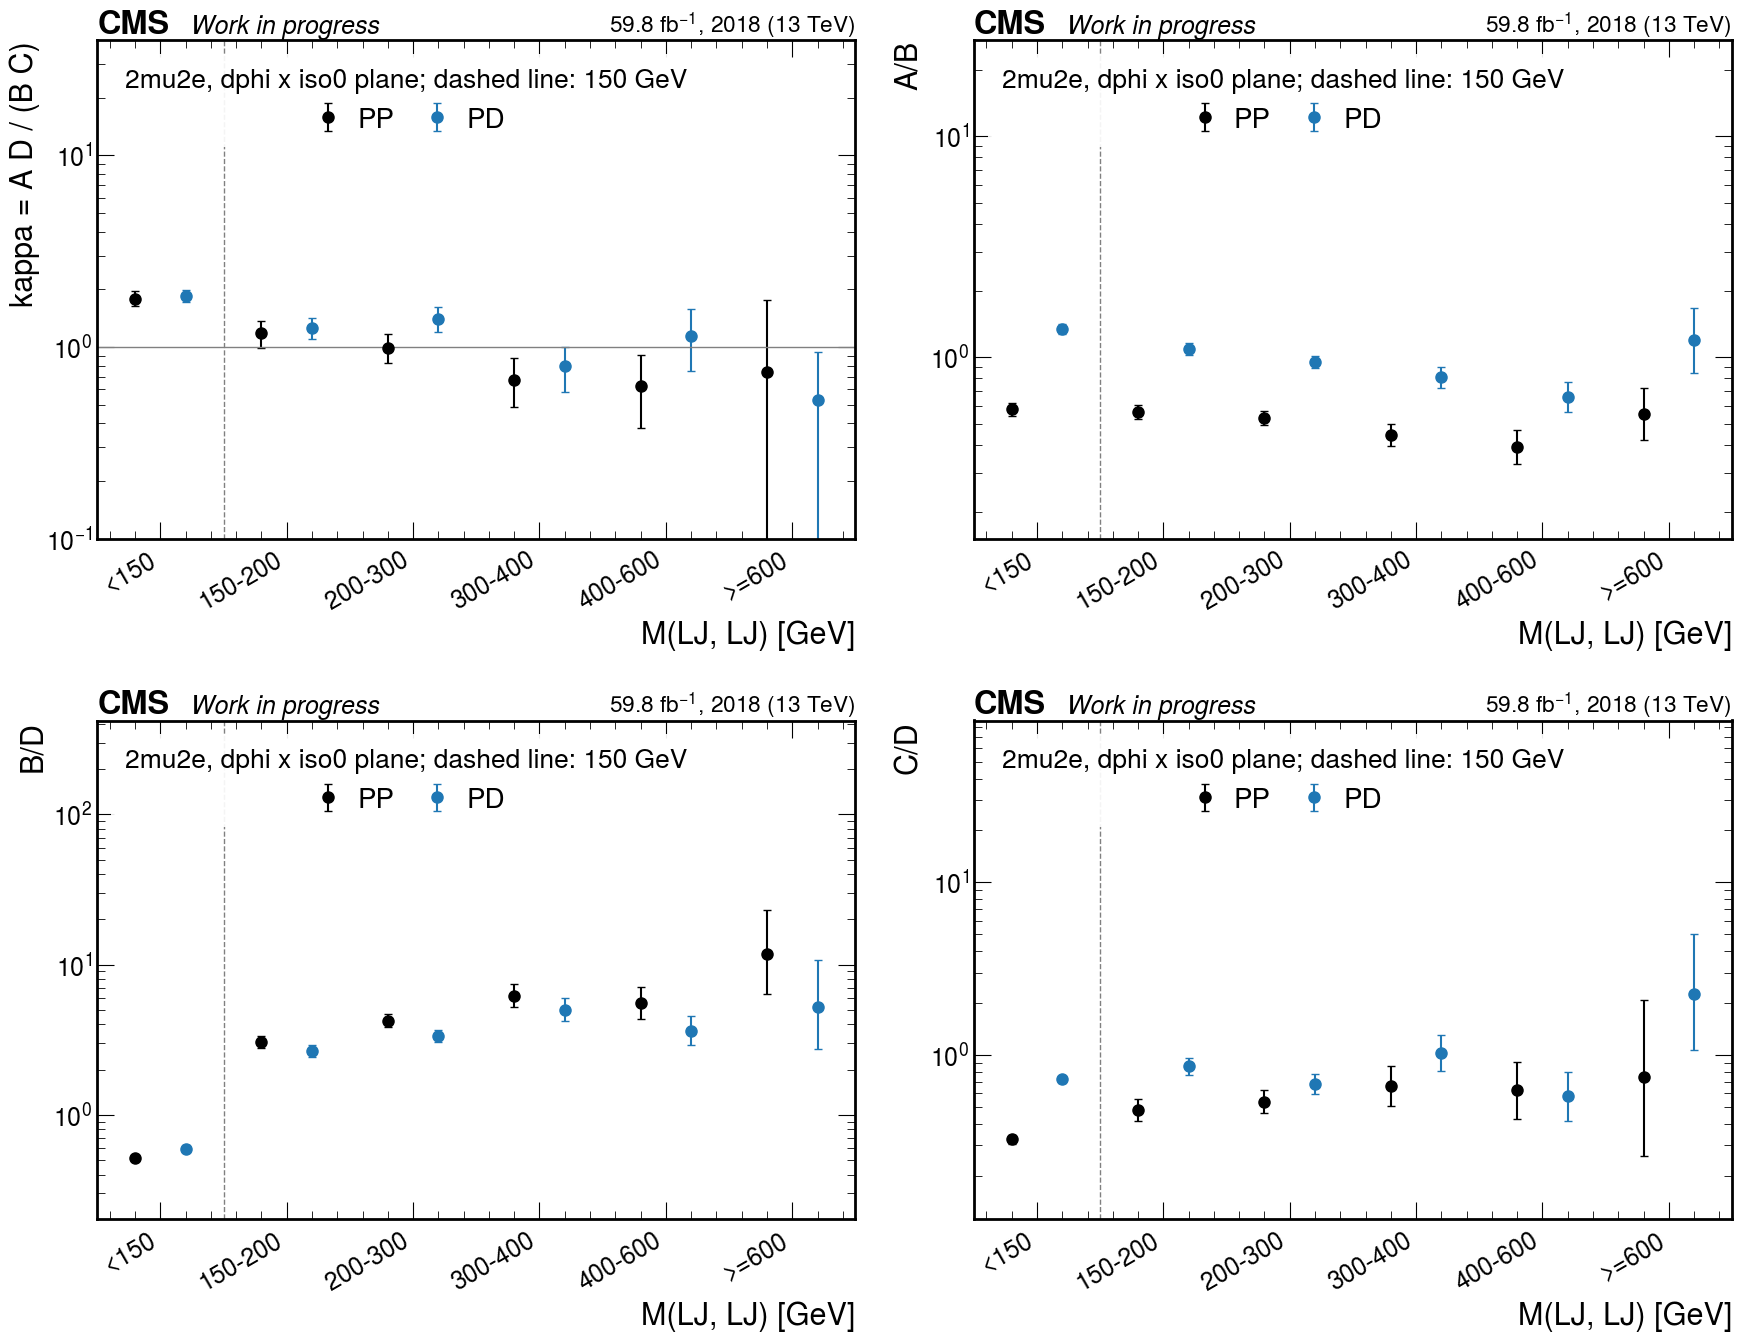

In [3]:
print("the planes with A open, nominal boundaries, then the previous boundaries")
display(el.closure_table([(f"{label}, {p}", d2, cfg, p) for label, cfg in WINDOWS for p in ("PP", "PD", "DP")]))
display(el.closure_table([(f"{label} (previous boundaries), {p}", d2, dataclasses.replace(BUFFERED, mass=cfg.mass), p)
                          for label, cfg in WINDOWS for p in ("PP", "PD")]))
print("one buffer at a time, M >= 150 GeV")
display(el.closure_table([("isolation buffer only (dphi 2.4/2.4 x iso0 0.25/0.5), " + p, d2, dataclasses.replace(NOMINAL, fail0=0.5), p) for p in ("PP", "PD")]
                         + [("dphi buffer only (dphi 2.4/2 x iso0 0.25/0.25), " + p, d2, dataclasses.replace(NOMINAL, dphi_fail=2.0), p) for p in ("PP", "PD")]))
print("by DSA class of the muon LJ, M >= 150 GeV")
DSA_SPLITS = (None, "dsa0", "dsa1+", "dsa2+", "mu0", "mu1-2", "mu3+")
display(el.class_grid_table(d2, NOMINAL, ("PP", "PD", "DP"), DSA_SPLITS))
print("against the LJ-pair mass")
display(ps.mass_table(d2, NOMINAL, planes=("PP", "PD")))
fig = pp.mass_figure(d2, planes=("PP", "PD"), cfg=NOMINAL)
plt.show()

### 2.2 The search plane below 150 GeV, and why the prompt planes fail there

Below 150 GeV every corner is open, including A of the DD plane. The DD plane is the one region
with the search plane's own objects and an open A; PP and PD in the same window are shown for
completeness, not as validation regions.

DD below 150 GeV gives **κ = 1.26 ± 0.44** on 41/32/53/52 events: consistent with one, and with
the 1.20 of PD above 150 GeV, at 35% precision. PP and PD fail there by a factor 1.8 (1.79 ± 0.16
and 1.86 ± 0.13): low-mass LJ pairs are mostly not back-to-back (C + D far exceeds A + B in both
planes, the reverse of the high-mass window), a different population in which the isolation and
the angle are correlated. Low mass is therefore not a validation window for the prompt planes;
its value is the DD line.

In [4]:
display(el.closure_table([(f"M < 150, {p}", d2, LOW, p) for p in PLANES]))
display(el.class_grid_table(d2, LOW, PLANES, (None, "dsa0", "dsa1+")))

,validation region,plane,A observed,B C/D,kappa,kappa - 1 [%],precision [%],verdict
0,"M < 150, PP",PP,382,213.7 ± 14.7,1.79 ± 0.16,+79 (-16/+16),9,fails (target 15%)
1,"M < 150, DP",DP,14,11.4 ± 3.5,1.23 -0.55 +0.64,+23 (-55/+64),52,imprecise (target 15%)
2,"M < 150, PD",PD,878,473.2 ± 28.8,1.86 ± 0.13,+86 (-13/+13),7,fails (target 15%)
3,"M < 150, DD",DD,41,32.6 ± 8.6,1.26 ± 0.44,+26 (-44/+43),35,imprecise (target 15%)


,plane,b-tag,A,B,C,D,A/B,B/D,C/D,kappa,N_eff A
0,PP,all,382,659,415,1280,0.58 -0.04 +0.04,0.51 ± 0.03,0.32 -0.02 +0.02,1.79 ± 0.16,382
1,PP:dsa0,all,363,604,362,1123,0.60 -0.04 +0.04,0.54 -0.03 +0.03,0.32 -0.02 +0.02,1.86 ± 0.18,363
2,PP:dsa1+,all,19,55,53,157,0.35 -0.09 +0.12,0.35 -0.05 +0.06,0.34 -0.05 +0.06,1.02 -0.33 +0.39,19
3,DP,all,14,24,27,57,0.58 -0.19 +0.28,0.42 -0.10 +0.13,0.47 -0.11 +0.14,1.23 -0.55 +0.64,14
4,DP:dsa0,all,9,12,20,31,0.75 -0.31 +0.53,0.39 -0.13 +0.19,0.65 -0.18 +0.25,1.16 -0.71 +0.80,9
5,DP:dsa1+,all,5,12,7,26,0.42 -0.21 +0.38,0.46 -0.16 +0.23,0.27 -0.11 +0.17,1.55 -1.13 +1.78,5
6,PD,all,878,653,795,1097,1.34 -0.07 +0.07,0.60 ± 0.03,0.72 ± 0.04,1.86 ± 0.13,878
7,PD:dsa0,all,803,586,651,939,1.37 -0.07 +0.08,0.62 -0.03 +0.03,0.69 -0.04 +0.04,1.98 ± 0.15,803
8,PD:dsa1+,all,75,67,144,158,1.12 -0.19 +0.22,0.42 -0.06 +0.07,0.91 -0.10 +0.12,1.23 ± 0.27,75
9,DD,all,41,32,53,52,1.28 -0.30 +0.39,0.62 -0.14 +0.17,1.02 -0.20 +0.24,1.26 ± 0.44,41


### 2.3 The classes of the muon LJ

A muon LJ is prompt when its best-tracked muon has at least three pixel hits; a DSA muon has none,
so a prompt LJ with a DSA partner is a well-tracked PF muon clustered with a muon-system-only
track. The two classes have different isolation pass/fail ratios in every plane, and the search
plane's sidebands hold a far larger DSA share than PD's A: the ratios borrowed from PD must
therefore be taken per class. The figure shows A/B and κ against the muon LJ's pixel-hit class in
the three populations where the classes can be compared.

In PD at M ≥ 150 GeV, A/B is 1.04 ± 0.04 for PF-only muon LJs (1253/1203) and 0.45 −0.06 +0.07
for DSA-containing ones (90/198); A/C is 4.2 and 2.0, A/D 3.5 and 1.2. Seven per cent of PD's A
and 13–17% of its sidebands carry a DSA muon. In the signal's search region 46–73% of the events
do (section 3.3), and in the search plane's sidebands 44% of B and 45% of D (section 3.1) — so an
inclusive ratio from PD, weighted by PD's 7–14%, would be the wrong mixture for DD.

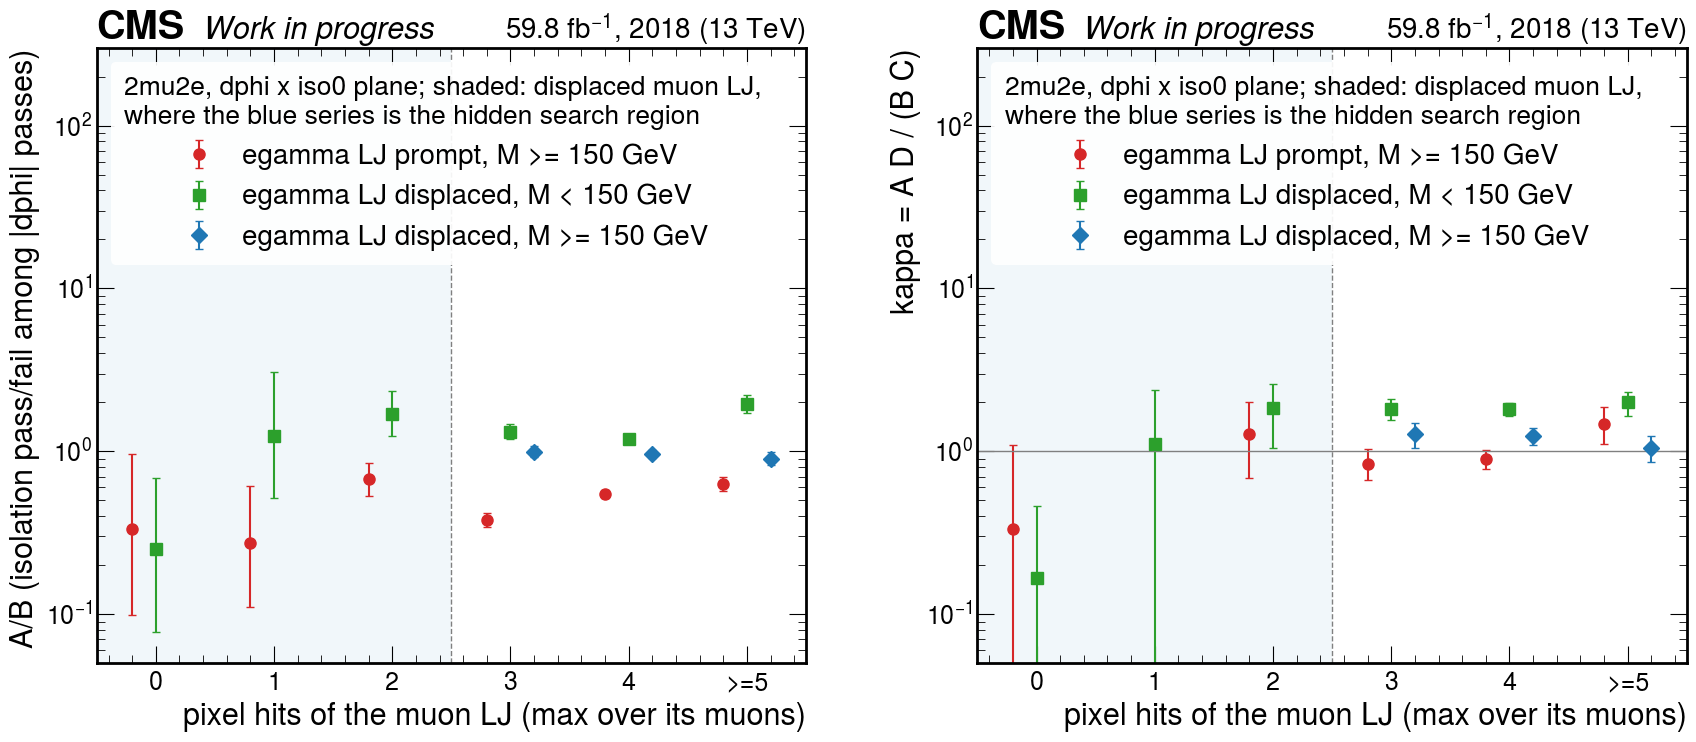

the borrowed factors per class and window, and C/D in PD


,window,class,PD A/B/C/D,A/B PD,A/C PD,A/D PD,C/D PD
0,M >= 150,dsa0,1253/1203/301/359,1.04 ± 0.04,4.16 -0.27 +0.29,3.49 -0.21 +0.22,0.84 -0.07 +0.07
1,M >= 150,dsa1+,90/198/46/74,0.45 -0.06 +0.07,1.96 -0.35 +0.43,1.22 -0.19 +0.22,0.62 -0.12 +0.14
2,M >= 150,all,1343/1401/347/433,0.96 ± 0.04,3.87 -0.23 +0.25,3.10 -0.17 +0.18,0.80 -0.06 +0.06
3,150-300,dsa0,994/903/237/300,1.10 ± 0.05,4.19 -0.30 +0.33,3.31 -0.22 +0.23,0.79 -0.07 +0.07
4,150-300,dsa1+,74/146/39/54,0.51 -0.07 +0.08,1.90 -0.37 +0.46,1.37 -0.24 +0.30,0.72 -0.15 +0.19
5,150-300,all,1068/1049/276/354,1.02 ± 0.05,3.87 -0.26 +0.28,3.02 -0.18 +0.20,0.78 -0.06 +0.07
6,M >= 300,dsa0,259/300/64/59,0.86 -0.07 +0.08,4.05 -0.56 +0.65,4.39 -0.63 +0.74,1.08 -0.19 +0.24
7,M >= 300,dsa1+,16/52/7/20,0.31 -0.09 +0.12,2.29 -0.96 +1.72,0.80 -0.26 +0.38,0.35 -0.15 +0.24
8,M >= 300,all,275/352/71/79,0.78 -0.06 +0.07,3.87 -0.51 +0.59,3.48 -0.44 +0.51,0.90 -0.15 +0.17


In [5]:
fig = pp.pixel_class_figure(d2, NOMINAL)
plt.show()
print("the borrowed factors per class and window, and C/D in PD")
display(el.class_factors_table(d2, WINDOWS)[["window", "class", "PD A/B/C/D", "A/B PD", "A/C PD", "A/D PD", "C/D PD"]])

## 3. The 2μ2e estimate

### 3.1 Four routes to A of the search plane

The direct estimate B C/D from DD's own sidebands, and the three borrowed ones — B × (A/B),
C × (A/C), D × (A/D), with the ratio from PD per DSA class and summed — per mass window, the
inclusive borrowed forms beside them for comparison. Then the same four routes from PP into DP,
the plane with a prompt egamma LJ, where A is observed: the open analog of the estimate. Then the
per-class factors with the sideband-only test of the borrowing, C/D of DD against C/D of PD per
class. Last, the search plane by class.

Over the whole high-mass window the search plane's sidebands hold 78, 17 and 29 events (B, C,
D), 44% of B and 45% of D with a DSA muon in the muon LJ. The four routes give **46 ± 15** (direct,
B C/D), **61 ± 8** (B × A/B), **60 ± 16** (C × A/C) and **72 ± 15** (D × A/D) events. Taken
inclusively the borrowed routes would read 75, 66 and 90, 10–25% higher, because the sidebands'
DSA share is three times PD's and the DSA class has the smaller ratios.

The four routes are not independent measurements. All of them use the search plane's own
sidebands, and each borrowed route equals the direct one times an implied κ of the search plane:
1.34 (B route), 1.31 (C) and 1.57 (D), against the 1.00 the direct route assumes. The spread between
them is mostly the Poisson scatter of C (17 events) and D (29), which enter the direct route at
± 33%; it is a consistency check, not a systematic uncertainty, and an implied κ$_{DD}$ of 1.3 ± 0.5
is consistent with the 0.97, 1.20 and 1.02 of the open planes. What the comparison does say is that
the direct and the borrowed estimates agree within their statistics.

The B route's own assumption — that the muon LJ's isolation pass/fail ratio among back-to-back
events, per DSA class, does not change when the muon LJ goes from prompt to displaced, the egamma
LJ displaced in both planes — has two open tests. The second table applies the same four routes
from PP into DP, the same step with a prompt egamma LJ: over the whole window the B route gives
33.2 ± 4.5 against 44 observed (observed over predicted 1.32 ± 0.27, and above one in each window:
1.27 ± 0.33 at 150–300 GeV, 1.5 ± 0.5 above 300 GeV, 1.2 ± 0.4 below 150 GeV), its inclusive form
38.7 ± 4.8, the C and D routes 45.0 ± 13.8 and 45.8 ± 10.2 and the direct route 43.3 ± 14.9. Below
150 GeV, where the search plane's A is open (41 events), the routes give 33 ± 9 (direct) and
41 ± 8, 45 ± 7 and 36 ± 6 (per class), the inclusive forms 43, 58 and 42: the B route reads
1.00 ± 0.25 there. The two tests average 1.15 ± 0.18, consistent with one; their non-closure and
precision added in quadrature give 23%, and section 6 assigns 25%. Were the search plane to follow
DP rather than its own low-mass window, the estimate would read 80, just outside that band. The
same tests cannot tell the per-class form from the inclusive one, which reads 1.14 ± 0.22 and
0.95 ± 0.23 in them; the per-class form is kept as the one that follows from the different class
mixtures, and the inclusive form (75) lies inside the band.

The sideband test in the third table compares C/D of the search plane with C/D of PD per class:
0.59 −0.17 +0.24 against 0.80 ± 0.06, a ratio of 0.73 −0.22 +0.31 (per class 0.89 −0.34 +0.51 and
0.62 −0.34 +0.57; 0.54 −0.19 +0.28 at 150–300 GeV, 1.6 standard deviations low). Equal C/D ratios
are what the B route needs if the search plane shares PD's κ, and the test resolves that at 30%: it
is consistent with one and with a 30% deficit. The direct route and the inclusive B route differ by
exactly this ratio divided by κ$_{PD}$, 0.73/1.20 = 0.61.

Per window the picture is thinner. At 150–300 GeV the routes spread from 22 ± 9 (direct) through
41 ± 7 and 39 ± 13 to 65 ± 14 (D route); above 300 GeV, where the search plane holds 26/6/3
events, the direct route is 52 ± 38, the B and C routes 19 ± 4 and 21 ± 10 and the D route 6 ± 5.
With three D events the routes that divide by D or multiply it say nothing there, and the B route
carries that window; its one test above 300 GeV is the PP → DP analog, 15 observed against
10.2 ± 2.4 predicted.

In [6]:
display(el.routes_table(d2, WINDOWS + [("M < 150 (A open)", LOW)]))
print("the open analog: the same four routes from PP into DP (egamma LJ prompt), where A of DP is observed")
display(el.routes_table(d2, WINDOWS + [("M < 150", LOW)], ref_plane="PP", search="DP"))
print("the factors per class; the last column tests the borrowing on the open sidebands")
display(el.class_factors_table(d2, WINDOWS + [("M < 150 (A open)", LOW)]))
print("the search plane by class of the muon LJ")
display(el.class_grid_table(d2, NOMINAL, ("DD",), DSA_SPLITS))

,window,DD B/C/D,direct B C/D,B x A/B per class,B x A/B inclusive,C x A/C per class,C x A/C inclusive,D x A/D per class,D x A/D inclusive,DD A observed
0,M >= 150,78/17/29,45.7 ± 14.9,61.3 ± 8.0,74.8 ± 9.0,59.7 ± 15.6,65.8 ± 16.5,71.7 ± 15.3,89.9 ± 17.5,blind
1,150-300,52/11/26,22.0 ± 8.5,41.2 ± 6.6,52.9 ± 7.7,39.2 ± 12.7,42.6 ± 13.2,64.8 ± 14.4,78.4 ± 16.2,blind
2,M >= 300,26/6/3,52.0 ± 38.2,18.6 ± 4.2,20.3 ± 4.4,20.8 -9.2 +9.7,23.2 ± 10.1,6.0 ± 4.7,10.4 ± 6.2,blind
3,M < 150 (A open),32/53/52,32.6 ± 8.6,40.8 ± 7.9,43.0 ± 8.0,45.4 ± 7.4,58.5 ± 8.6,35.7 ± 5.6,41.6 ± 6.1,41


the open analog: the same four routes from PP into DP (egamma LJ prompt), where A of DP is observed


,window,DP B/C/D,direct B C/D,B x A/B per class,B x A/B inclusive,C x A/C per class,C x A/C inclusive,D x A/D per class,D x A/D inclusive,DP A observed
0,M >= 150,75/15/26,43.3 ± 14.9,33.2 ± 4.5,38.7 ± 4.8,45.0 ± 13.8,59.2 ± 16.1,45.8 ± 10.2,54.7 ± 11.3,44
1,150-300,47/12/17,33.2 ± 13.4,22.8 ± 4.0,25.7 ± 4.0,37.6 ± 12.6,46.3 ± 14.1,28.2 ± 7.6,33.1 ± 8.4,29
2,M >= 300,28/3/9,9.3 ± 6.5,10.2 ± 2.4,12.3 ± 2.6,7.0 -5.1 +11.0,12.7 ± 7.7,22.9 -9.4 +12.7,24.9 ± 9.2,15
3,M < 150,24/27/57,11.4 ± 3.5,11.4 -2.7 +2.8,13.9 ± 3.0,22.6 ± 4.9,24.9 ± 5.1,13.2 ± 2.2,17.0 ± 2.5,14


the factors per class; the last column tests the borrowing on the open sidebands


,window,class,DD B/C/D,PD A/B/C/D,A/B PD,A/C PD,A/D PD,C/D PD,C/D DD,C/D DD over PD
0,M >= 150,dsa0,44/12/16,1253/1203/301/359,1.04 ± 0.04,4.16 -0.27 +0.29,3.49 -0.21 +0.22,0.84 -0.07 +0.07,0.75 -0.27 +0.43,0.89 -0.34 +0.51
1,M >= 150,dsa1+,34/5/13,90/198/46/74,0.45 -0.06 +0.07,1.96 -0.35 +0.43,1.22 -0.19 +0.22,0.62 -0.12 +0.14,0.38 -0.19 +0.35,0.62 -0.34 +0.57
2,M >= 150,all,78/17/29,1343/1401/347/433,0.96 ± 0.04,3.87 -0.23 +0.25,3.10 -0.17 +0.18,0.80 -0.06 +0.06,0.59 -0.17 +0.24,0.73 -0.22 +0.31
3,150-300,dsa0,25/8/15,994/903/237/300,1.10 ± 0.05,4.19 -0.30 +0.33,3.31 -0.22 +0.23,0.79 -0.07 +0.07,0.53 -0.22 +0.37,0.68 -0.29 +0.47
4,150-300,dsa1+,27/3/11,74/146/39/54,0.51 -0.07 +0.08,1.90 -0.37 +0.46,1.37 -0.24 +0.30,0.72 -0.15 +0.19,0.27 -0.16 +0.34,0.38 -0.24 +0.48
5,150-300,all,52/11/26,1068/1049/276/354,1.02 ± 0.05,3.87 -0.26 +0.28,3.02 -0.18 +0.20,0.78 -0.06 +0.07,0.42 -0.15 +0.22,0.54 -0.19 +0.28
6,M >= 300,dsa0,19/4/1,259/300/64/59,0.86 -0.07 +0.08,4.05 -0.56 +0.65,4.39 -0.63 +0.74,1.08 -0.19 +0.24,4.00 -3.09 +24.45,3.69 -2.96 +22.55
7,M >= 300,dsa1+,7/2/2,16/52/7/20,0.31 -0.09 +0.12,2.29 -0.96 +1.72,0.80 -0.26 +0.38,0.35 -0.15 +0.24,1.00 -0.77 +3.40,2.86 -2.86 +9.78
8,M >= 300,all,26/6/3,275/352/71/79,0.78 -0.06 +0.07,3.87 -0.51 +0.59,3.48 -0.44 +0.51,0.90 -0.15 +0.17,2.00 -1.20 +3.32,2.23 -1.40 +3.72
9,M < 150 (A open),dsa0,20/25/29,803/586/651/939,1.37 -0.07 +0.08,1.23 -0.06 +0.07,0.86 ± 0.04,0.69 -0.04 +0.04,0.86 -0.23 +0.31,1.24 -0.34 +0.45


the search plane by class of the muon LJ


,plane,b-tag,A,B,C,D,A/B,B/D,C/D,kappa,N_eff A
0,DD,all,blind,78,17,29,n/a,2.69 -0.57 +0.74,0.59 -0.17 +0.24,n/a,blind
1,DD:dsa0,all,blind,44,12,16,n/a,2.75 -0.77 +1.10,0.75 -0.27 +0.43,n/a,blind
2,DD:dsa1+,all,blind,34,5,13,n/a,2.62 -0.82 +1.22,0.38 -0.19 +0.35,n/a,blind
3,DD:dsa2+,all,blind,8,1,1,n/a,8.00 -5.90 +43.60,1.00 -0.91 +10.08,n/a,blind
4,DD:mu0,all,blind,15,2,4,n/a,3.75 -1.86 +4.13,0.50 -0.36 +1.10,n/a,blind
5,DD:mu1-2,all,blind,63,15,25,n/a,2.52 -0.58 +0.77,0.60 -0.19 +0.27,n/a,blind


### 3.2 What the simulation says, and what it cannot

The simulated background per process group and region of the search plane and of PD, with the
effective counts. The simulation is not used in the estimate; this is the record of why.

The simulation puts 32 ± 15 events in A of the search plane (effective count 4.8, all QCD) and
157 ± 119 in B — one QCD event of weight ninety against 78 observed — and under-predicts A of PD by
a factor 2.8 (478 ± 145 against 1343 observed, of which Drell–Yan is 134). With one to seven
effective events per region of the search plane it neither confirms nor contradicts an estimate
of sixty, and it is not used.

In [7]:
print("simulation per process group, M >= 150 GeV (luminosity-scaled; N_eff = (sum w)^2 / sum w^2)")
display(ps.mc_composition_table(g2, d2, "2mu2e", NOMINAL, planes=("DD", "PD")))
mc2 = io.add_cubes([c["2mu2e"] for c in g2.values()])
display(el.mc_region_table(mc2, WINDOWS, ("DD", "PD")))
del mc2, g2

simulation per process group, M >= 150 GeV (luminosity-scaled; N_eff = (sum w)^2 / sum w^2)


,plane,region,data,simulation,N_eff,DY,QCD,diboson,ttbar,kappa (simulation)
0,DD,A,blind,32.3 ± 14.7,4.8,0.0,32.3,0.0,0.0,0.31 ± 0.34
1,DD,B,78,157.0 ± 118.9,1.7,0.0,150.5,0.0,6.5,
2,DD,C,17,19.2 ± 10.9,3.1,3.3,15.9,0.0,0.0,
3,DD,D,29,28.7 ± 10.7,7.2,0.0,28.7,0.0,0.0,
4,PD,A,1343,477.9 ± 144.7,10.9,134.3,309.9,1.0,32.7,0.58 ± 0.33
5,PD,B,1401,1574.7 ± 268.2,34.5,9.5,1498.9,0.8,65.5,
6,PD,C,347,544.7 ± 207.6,6.9,77.9,453.5,0.2,13.1,
7,PD,D,433,1041.8 ± 252.7,17.0,0.0,1012.1,0.2,29.5,


,window,plane,A,B,C,D
0,M >= 150,DD,32.28 ± 14.71 (N_eff 4.8),157.03 ± 118.93 (N_eff 1.7),19.16 ± 10.89 (N_eff 3.1),28.66 ± 10.67 (N_eff 7.2)
1,M >= 150,PD,477.91 ± 144.71 (N_eff 10.9),1574.74 ± 268.21 (N_eff 34.5),544.74 ± 207.61 (N_eff 6.9),1041.77 ± 252.66 (N_eff 17.0)
2,150-300,DD,23.96 ± 12.74 (N_eff 3.5),135.01 ± 118.47 (N_eff 1.3),18.00 ± 10.87 (N_eff 2.7),18.54 ± 7.69 (N_eff 5.8)
3,150-300,PD,270.20 ± 79.87 (N_eff 11.4),1247.44 ± 256.48 (N_eff 23.7),398.75 ± 170.15 (N_eff 5.5),887.82 ± 241.82 (N_eff 13.5)
4,M >= 300,DD,8.32 ± 7.36 (N_eff 1.3),22.01 ± 10.50 (N_eff 4.4),1.17 ± 0.69 (N_eff 2.9),10.13 ± 7.39 (N_eff 1.9)
5,M >= 300,PD,207.71 ± 120.67 (N_eff 3.0),327.30 ± 78.45 (N_eff 17.4),145.99 ± 118.95 (N_eff 1.5),153.95 ± 73.22 (N_eff 4.4)


### 3.3 Signal in the regions read from

Each signal point's yield in every region the estimate and the validation read, as a fraction of
its own yield in the search region A of DD (M ≥ 150 GeV), with the yield at the stored cross
section in brackets; then the signal's DSA-class composition in the search region and its yield
per mass window.

The sidebands of the search plane are signal-poor: B holds 0.4–1.1% of A's yield, C 1.6–4.4% and D
nothing (with the previous boundaries B held 0.1–0.2% and C 0.5–1.6%, so the two former buffer
bands, iso0 0.25–0.5 at $|\Delta\phi| \ge 2.4$ and $|\Delta\phi|$ 2.0–2.4 at iso0 < 0.25, account
for 0.3–0.9% and 1.1–2.8%). At the stored cross sections C holds up to 1.4 signal events of its
17, and at an exclusion-level signal of about 30 events in A the former $|\Delta\phi|$ band alone
would hold 0.3–0.8, C 0.5–1.3 (up to 8% of its 17 events, which enter the direct and the C route),
B 0.1–0.3 of its 78 and D none. The validation planes take more: A of PD holds 18–41% of the search region's yield — signal events
whose muon LJ was caught with three or more pixel hits — which is at most 1.7% of PD's 1343 data
events at the stored cross sections; A of DP holds 7–17%, up to 9.7 events against 44 observed; A
of PP 1–7%, up to 4 events against 797. The B route reads A and B of PD per class: A of PD:dsa0 holds 14–32% of the search region's
signal (up to 19 events against 1253 observed), A of PD:dsa1+ 2.5–9% (up to 4.7 against 90), and
the B cells 0.3% or less; at an exclusion-level signal of 30 events that is 0.8% of A in PD:dsa0
and 3% in PD:dsa1+, which together move the B route by less than one event. Of the signal in the search region 46–73% has a DSA muon
in the muon LJ (27–54% none, 29–53% one, 8–30% two or more), which is why the DSA class cannot be
vetoed and why the borrowed factors are taken per class. For the 500–1000 GeV points more than 99.8% of the yield lies above
300 GeV; the 200 GeV point lies entirely below it.

In [8]:
display(el.signal_cells_table(BASE, SIGNAL_POINTS["2mu2e"], "2mu2e", [
    ("A DD, M >= 150 (search region)", NOMINAL, "DD", "A"),
    ("B DD, M >= 150", NOMINAL, "DD", "B"), ("C DD, M >= 150", NOMINAL, "DD", "C"), ("D DD, M >= 150", NOMINAL, "DD", "D"),
    ("B DD with the previous boundaries (iso0 >= 0.5)", BUFFERED, "DD", "B"),
    ("C DD with the previous boundaries (|dphi| < 2.0)", BUFFERED, "DD", "C"),
    ("A PD, M >= 150", NOMINAL, "PD", "A"), ("B PD, M >= 150", NOMINAL, "PD", "B"),
    ("A PD:dsa0, M >= 150", NOMINAL, "PD:dsa0", "A"), ("B PD:dsa0, M >= 150", NOMINAL, "PD:dsa0", "B"),
    ("A PD:dsa1+, M >= 150", NOMINAL, "PD:dsa1+", "A"), ("B PD:dsa1+, M >= 150", NOMINAL, "PD:dsa1+", "B"),
    ("A PP, M >= 150", NOMINAL, "PP", "A"), ("A DP, M >= 150", NOMINAL, "DP", "A"),
    ("A DD, M < 150", LOW, "DD", "A")]))
print("the DSA class of the muon LJ in the search region (share of A), and the yield per mass window")
display(el.signal_cells_table(BASE, SIGNAL_POINTS["2mu2e"], "2mu2e", [
    ("A DD, M >= 150 (search region)", NOMINAL, "DD", "A"),
    ("no DSA muon", NOMINAL, "DD:dsa0", "A"), ("one DSA muon", NOMINAL, "DD:dsa1", "A"), ("two or more", NOMINAL, "DD:dsa2+", "A")]))
display(el.signal_a_table(BASE, SIGNAL_POINTS["2mu2e"], "2mu2e", WINDOWS, ("DD",), prefix="abcd8d"))

,region,2Mu2E_200GeV_0p25GeV_1p0mm,2Mu2E_500GeV_0p25GeV_0p4mm,2Mu2E_800GeV_0p25GeV_0p25mm,2Mu2E_1000GeV_0p25GeV_0p2mm,2Mu2E_800GeV_1p2GeV_1p2mm,2Mu2E_1000GeV_1p2GeV_0p96mm,2Mu2E_800GeV_0p25GeV_1p2mm
0,"A DD, M >= 150 (search region)",1.000 [0.56],1.000 [14.86],1.000 [58.85],1.000 [1.48],1.000 [63.10],1.000 [2.05],1.000 [21.48]
1,"B DD, M >= 150",0.011 [0.01],0.005 [0.07],0.004 [0.23],0.005 [0.01],0.006 [0.38],0.006 [0.01],0.006 [0.12]
2,"C DD, M >= 150",0.044 [0.02],0.028 [0.41],0.024 [1.39],0.023 [0.03],0.020 [1.29],0.016 [0.03],0.031 [0.67]
3,"D DD, M >= 150",0.000 [0.00],0.000 [0.00],0.000 [0.00],0.000 [0.00],0.000 [0.00],0.000 [0.00],0.000 [0.00]
4,B DD with the previous boundaries (iso0 >= 0.5),0.002 [0.00],0.001 [0.02],0.001 [0.08],0.002 [0.00],0.002 [0.14],0.002 [0.00],0.002 [0.04]
5,C DD with the previous boundaries (|dphi| < 2.0),0.016 [0.01],0.009 [0.14],0.008 [0.48],0.008 [0.01],0.006 [0.41],0.005 [0.01],0.012 [0.25]
6,"A PD, M >= 150",0.239 [0.13],0.299 [4.44],0.382 [22.50],0.415 [0.61],0.332 [20.98],0.349 [0.72],0.180 [3.88]
7,"B PD, M >= 150",0.002 [0.00],0.002 [0.03],0.002 [0.11],0.003 [0.00],0.002 [0.16],0.003 [0.01],0.001 [0.02]
8,"A PD:dsa0, M >= 150",0.215 [0.12],0.252 [3.74],0.303 [17.82],0.323 [0.48],0.304 [19.19],0.311 [0.64],0.143 [3.07]
9,"B PD:dsa0, M >= 150",0.001 [0.00],0.001 [0.01],0.001 [0.07],0.002 [0.00],0.002 [0.11],0.002 [0.00],0.001 [0.01]


the DSA class of the muon LJ in the search region (share of A), and the yield per mass window


,region,2Mu2E_200GeV_0p25GeV_1p0mm,2Mu2E_500GeV_0p25GeV_0p4mm,2Mu2E_800GeV_0p25GeV_0p25mm,2Mu2E_1000GeV_0p25GeV_0p2mm,2Mu2E_800GeV_1p2GeV_1p2mm,2Mu2E_1000GeV_1p2GeV_0p96mm,2Mu2E_800GeV_0p25GeV_1p2mm
0,"A DD, M >= 150 (search region)",1.000 [0.56],1.000 [14.86],1.000 [58.85],1.000 [1.48],1.000 [63.10],1.000 [2.05],1.000 [21.48]
1,no DSA muon,0.519 [0.29],0.440 [6.55],0.405 [23.82],0.383 [0.57],0.537 [33.90],0.530 [1.09],0.267 [5.75]
2,one DSA muon,0.292 [0.16],0.409 [6.08],0.492 [28.97],0.533 [0.79],0.335 [21.15],0.352 [0.72],0.435 [9.34]
3,two or more,0.189 [0.11],0.150 [2.23],0.103 [6.06],0.084 [0.12],0.128 [8.05],0.119 [0.24],0.298 [6.40]


,point,window,DD A
0,2Mu2E_200GeV_0p25GeV_1p0mm,M >= 150,0.56
1,2Mu2E_200GeV_0p25GeV_1p0mm,150-300,0.56
2,2Mu2E_200GeV_0p25GeV_1p0mm,M >= 300,0.00
3,2Mu2E_500GeV_0p25GeV_0p4mm,M >= 150,14.86
4,2Mu2E_500GeV_0p25GeV_0p4mm,150-300,0.02
5,2Mu2E_500GeV_0p25GeV_0p4mm,M >= 300,14.84
6,2Mu2E_800GeV_0p25GeV_0p25mm,M >= 150,58.85
7,2Mu2E_800GeV_0p25GeV_0p25mm,150-300,0.03
8,2Mu2E_800GeV_0p25GeV_0p25mm,M >= 300,58.82
9,2Mu2E_1000GeV_0p25GeV_0p2mm,M >= 150,1.48


## 4. The boundaries: the configuration scan

The nominal boundaries are one point of a family — the isolation working point and its fail
boundary, the $|\Delta\phi|$ pass and fail boundaries, the second object's isolation cut, the choice
of axes — that `plane_search_lib.config_grid` enumerates: 405 configurations on the
$|\Delta\phi|$ × iso0, iso0 × iso1 and $|\Delta\phi|$ × iso1 planes. Each is scored by its worst
|κ − 1| over the regions that *select* it (the search channel's PP) and checked on the regions that
*confirm* it (PD and DP), so that the choice is not tuned to the fluctuations of the region that
justifies it. A region whose κ is less precise than the 15% target cannot test it and is left out
of the worst deviation (counted as untestable). A configuration is only usable if the search
plane's B, C and D lie outside the hidden box ("DD in-plane estimate exists"); since the box is
A, that holds for every configuration whose sidebands start at or beyond A's edges. The reduced
cubes hold the four ABCD axes of one plane, which makes the scan take seconds. The last table
evaluates the estimate itself for the usable configurations of the $|\Delta\phi|$ × iso0 family
without buffers, to show how much the estimate depends on where the lines are drawn.

Of the 405 configurations, 291 keep the search plane's sidebands outside the hidden box. Among
them the unbuffered $|\Delta\phi|$ × iso0 configurations (18) give κ$_{PD}$ 1.11–1.27 (median 1.16)
and the buffered ones (162) 1.12–1.44 (median 1.24); the iso0 × iso1 family gives 1.31–1.38
unbuffered and 1.30–1.89 buffered, and the 21 configurations that use the egamma LJ's isolation as
the axis fail the other way, 0.45–0.79. For PP the unbuffered $|\Delta\phi|$ × iso0 configurations
give 0.58–1.01 and the buffered ones 0.56–1.08, and the iso0 × iso1 family closes PP (0.96–1.31,
58 of 90 within 15%) while failing PD. The 38 usable configurations with both planes within 20% of
one are all $|\Delta\phi|$ × iso0, and the ones with both closest to one are the unbuffered
boundaries at $|\Delta\phi|$ = 2.4 with iso0 at 0.25 or 0.3 (PP 0.97–1.01, PD 1.14–1.20), the
nominal among them; its $|\Delta\phi|$ edge is the search region's. PP's κ depends on where that edge
is drawn: among the unbuffered configurations with iso1 < 0.5 it is 0.77–0.81 at 2.0, 0.82–0.88 at
2.2 and 0.97–1.01 at 2.4 (1.00 at 2.6, a boundary whose C and D would reach into the hidden box),
while PD moves only between 1.12 and 1.20: the isolation and the angle of the leading muon LJ are
not quite independent in PP below $|\Delta\phi| \approx 2.4$, and PP's closure at the nominal
boundary is a closure at that boundary. The scan's loosest working point for the second object is
iso1 < 1; it is a cut, not its absence — the isolation axis runs to 5, and 29% of the events in
PP's isolated back-to-back corner have iso1 ≥ 1 (printed below the scan) — and the configurations
that use it change the search region, so it is not adopted.

The last table, the estimate over the six unbuffered $|\Delta\phi|$ × iso0 configurations whose
sidebands stay open: the direct route moves between 38 and 46, the B route between 61 and 73, the
C route between 54 and 73 and the D route between 72 and 141: the D route moves most with the
$|\Delta\phi|$ boundary and the B route by 20%. The configurations with iso0 at 0.3 or $|\Delta\phi|$
below 2.4 define a larger A than the nominal one (by the open bands next to it, 5–6 events each,
visible as the change of B and C), so part of their movement is the region, not the method.

In [9]:
CFGS = ps.config_grid("dphi x iso0") + ps.config_grid("iso0 x iso1") + ps.config_grid("dphi x iso1")
R2 = {f"search {p}": el.reduce_plane(d2, p) for p in ("PP", "DP", "PD")}
scan2 = el.closure_scan(R2, CFGS, select=["search PP"], confirm=["search PD", "search DP"])
usable = scan2[scan2["DD in-plane estimate exists"]]
print(f"{len(scan2)} configurations, {len(usable)} keep the search plane's B, C and D outside the hidden box")
print("best 15 by the worst deviation of the selecting region, then the nominal configuration and the previous boundaries")
display(pd.concat([scan2.head(15), scan2[scan2["config"].isin([NOMINAL.label(), BUFFERED.label()])]]).round(3))
print("kappa of the search channel's PD among the usable configurations, by plane family and buffer")
def has_buffer(c):
    iso0, iso1, dphi = c.fail0 > c.wp0, c.fail1 > c.wp1, c.dphi_fail < c.dphi_pass
    return {"dphi x iso0": iso0 or dphi, "iso0 x iso1": iso0 or iso1, "dphi x iso1": iso1 or dphi}[c.kind]

by_label = {c.label(): c for c in CFGS}
fam = usable.copy()
fam["buffered"] = [has_buffer(by_label[label]) for label in fam["config"]]
for buffered, part in fam.groupby("buffered"):
    print("buffered" if buffered else "no buffer")
    display(el.kappa_by_family(part, "kappa search PD"))
print("the same for the search channel's PP")
for buffered, part in fam.groupby("buffered"):
    print("buffered" if buffered else "no buffer")
    display(el.kappa_by_family(part, "kappa search PP"))
k_pd = pd.DataFrame([el.parse_fmt(t) for t in scan2["kappa search PD"]], columns=["kappa", "minus", "plus"], index=scan2.index)
k_pp = pd.DataFrame([el.parse_fmt(t) for t in scan2["kappa search PP"]], columns=["kappa", "minus", "plus"], index=scan2.index)
close_pd = scan2[((k_pd["kappa"] - 1).abs() <= 0.15) & (k_pd[["minus", "plus"]].max(axis=1) / k_pd["kappa"] <= 0.15)]
print(f"the {len(close_pd)} configurations in which the search channel's PD is measured to 15% and within 15% of one")
display(close_pd[["config", "kappa search PD", "kappa search PP", "DD in-plane estimate exists"]])
both = scan2[((k_pd["kappa"] - 1).abs() <= 0.2) & ((k_pp["kappa"] - 1).abs() <= 0.2) & scan2["DD in-plane estimate exists"]]
print(f"the {len(both)} usable configurations with both PP and PD within 20% of one")
display(both[["config", "kappa search PP", "kappa search PD"]])
a_all = ps.regions(d2, dataclasses.replace(NOMINAL, wp1=None), "PP")["A"][0]
a_1 = ps.regions(d2, dataclasses.replace(NOMINAL, wp1=1.0), "PP")["A"][0]
print(f"PP, A without any iso1 cut: {a_all:.0f} events; with iso1 < 1: {a_1:.0f}; share at iso1 >= 1: {1 - a_1 / a_all:.0%}")
print("the estimate for the usable, unbuffered dphi x iso0 configurations with iso1 < 0.5, M >= 150 GeV")
stable = [c for c in ps.config_grid("dphi x iso0") if c.dd_open() and c.fail0 == c.wp0 and c.dphi_fail == c.dphi_pass and c.wp1 == 0.5]
rows = []
for c in stable:
    r = el.routes_table(d2, [("M >= 150", c)]).iloc[0]
    rows.append({"config": c.label(), "kappa PP": tl.fmt(ps.kappa(ps.regions(d2, c, "PP")), 2), "kappa PD": tl.fmt(ps.kappa(ps.regions(d2, c, "PD")), 2),
                 "DD B/C/D": r["DD B/C/D"], "direct B C/D": r["direct B C/D"], "B x A/B per class": r["B x A/B per class"],
                 "C x A/C per class": r["C x A/C per class"], "D x A/D per class": r["D x A/D per class"]})
display(pd.DataFrame(rows))

405 configurations, 291 keep the search plane's B, C and D outside the hidden box
best 15 by the worst deviation of the selecting region, then the nominal configuration and the previous boundaries


,config,kind,kappa search PP,kappa search PD,kappa search DP,worst |kappa-1| select,untestable select,worst |kappa-1| confirm,untestable confirm,all select within target,testable select within target,all confirm within target,testable confirm within target,DD in-plane estimate exists
0,"dphi 2.6/2.6 x iso0 0.25/0.25, iso1<0.5, M>=150",dphi x iso0,1.00 ± 0.09,1.17 ± 0.09,1.01 -0.39 +0.44,0.002,0,0.173,1,True,True,False,False,False
1,"iso0 0.25/0.5 x iso1 0.25/0.5, dphi>=2.6, M>=150",iso0 x iso1,1.00 ± 0.08,1.46 ± 0.14,1.96 -0.71 +0.76,0.002,0,0.461,1,True,True,False,False,True
2,"iso0 0.2/0.2 x iso1 0.25/0.5, dphi>=2, M>=150",iso0 x iso1,1.00 ± 0.07,1.41 ± 0.11,2.12 -0.63 +0.73,0.003,0,0.410,1,True,True,False,False,False
3,"iso0 0.2/0.5 x iso1 0.25/0.5, dphi>=2.6, M>=150",iso0 x iso1,1.00 ± 0.09,1.50 ± 0.14,2.03 -0.75 +0.84,0.004,0,0.501,1,True,True,False,False,True
4,"iso0 0.3/0.5 x iso1 0.25/0.5, dphi>=2.6, M>=150",iso0 x iso1,1.00 ± 0.08,1.43 ± 0.13,1.57 ± 0.57,0.005,0,0.429,1,True,True,False,False,True
5,"dphi 2.4/2.4 x iso0 0.2/0.5, iso1<0.5, M>=150",dphi x iso0,0.99 ± 0.12,1.26 ± 0.12,1.01 -0.47 +0.51,0.005,0,0.256,1,True,True,False,False,True
6,"dphi 2.4/2.4 x iso0 0.25/0.5, iso1<0.5, M>=150",dphi x iso0,0.99 ± 0.11,1.26 ± 0.12,1.03 -0.47 +0.50,0.006,0,0.259,1,True,True,False,False,True
7,"dphi 2.6/2.6 x iso0 0.2/0.5, iso1<1, M>=150",dphi x iso0,1.01 ± 0.08,1.18 ± 0.09,0.77 -0.28 +0.30,0.007,0,0.178,1,True,True,False,False,False
8,"iso0 0.25/0.25 x iso1 0.25/0.5, dphi>=2.4, M>=150",iso0 x iso1,0.99 ± 0.07,1.46 ± 0.12,1.91 -0.60 +0.69,0.008,0,0.463,1,True,True,False,False,True
9,"iso0 0.3/0.3 x iso1 0.25/0.5, dphi>=2.4, M>=150",iso0 x iso1,1.01 ± 0.07,1.43 ± 0.11,1.47 -0.45 +0.50,0.009,0,0.434,1,True,True,False,False,True


kappa of the search channel's PD among the usable configurations, by plane family and buffer
no buffer


,family,configurations,kappa defined,kappa min-max,median,precision min-max [%],interval above 1,interval below 1,interval covers 1,within 15% at that precision
0,dphi x iso0,18,18,1.11-1.27,1.16,7-13,16,0,2,7
1,iso0 x iso1,6,6,1.31-1.38,1.36,7-8,6,0,0,0
2,dphi x iso1,3,3,0.68-0.79,0.72,14-21,0,3,0,0


buffered


...

,config,kappa search PD,kappa search PP,DD in-plane estimate exists
10,"dphi 2.4/2.4 x iso0 0.3/0.3, iso1<0.5, M>=150",1.14 ± 0.10,1.01 ± 0.10,True
11,"dphi 2.4/2.4 x iso0 0.3/0.3, iso1<1, M>=150",1.11 ± 0.08,0.99 ± 0.08,True
24,"dphi 2.6/2.6 x iso0 0.3/0.3, iso1<1, M>=150",1.12 ± 0.08,1.02 ± 0.07,False
45,"dphi 2.6/2.6 x iso0 0.25/0.25, iso1<1, M>=150",1.14 ± 0.08,0.95 ± 0.07,False
46,"dphi 2.6/2.6 x iso0 0.2/0.2, iso1<1, M>=150",1.14 ± 0.08,0.95 ± 0.07,False
96,"dphi 2.2/2.2 x iso0 0.3/0.3, iso1<1, M>=150",1.13 ± 0.10,0.91 ± 0.08,True
137,"dphi 2.4/2.4 x iso0 0.2/0.2, iso1<1, M>=150",1.13 ± 0.09,0.87 ± 0.08,False
146,"dphi 2.4/2 x iso0 0.3/0.3, iso1<1, M>=150",1.15 ± 0.11,0.87 ± 0.09,True
153,"dphi 2.2/2 x iso0 0.3/0.3, iso1<1, M>=150",1.14 ± 0.11,0.86 ± 0.09,True
156,"dphi 2/2 x iso0 0.3/0.3, iso1<1, M>=150",1.14 ± 0.11,0.85 ± 0.09,True


the 38 usable configurations with both PP and PD within 20% of one


,config,kappa search PP,kappa search PD
10,"dphi 2.4/2.4 x iso0 0.3/0.3, iso1<0.5, M>=150",1.01 ± 0.10,1.14 ± 0.10
11,"dphi 2.4/2.4 x iso0 0.3/0.3, iso1<1, M>=150",0.99 ± 0.08,1.11 ± 0.08
26,"dphi 2.4/2.4 x iso0 0.3/0.5, iso1<1, M>=150",1.03 ± 0.09,1.18 ± 0.10
34,"dphi 2.4/2.4 x iso0 0.25/0.25, iso1<0.5, M>=150",0.97 ± 0.10,1.20 ± 0.10
65,"dphi 2.4/2.4 x iso0 0.25/0.25, iso1<1, M>=150",0.93 ± 0.08,1.16 ± 0.09
96,"dphi 2.2/2.2 x iso0 0.3/0.3, iso1<1, M>=150",0.91 ± 0.08,1.13 ± 0.10
135,"dphi 2.2/2.2 x iso0 0.3/0.3, iso1<0.5, M>=150",0.88 ± 0.10,1.16 ± 0.11
138,"dphi 2.6/2 x iso0 0.3/0.3, iso1<1, M>=150",0.87 ± 0.09,1.16 ± 0.11
146,"dphi 2.4/2 x iso0 0.3/0.3, iso1<1, M>=150",0.87 ± 0.09,1.15 ± 0.11
150,"dphi 2/2 x iso0 0.3/0.5, iso1<0.5, M>=150",0.86 ± 0.12,1.20 ± 0.14


PP, A without any iso1 cut: 1770 events; with iso1 < 1: 1265; share at iso1 >= 1: 29%
the estimate for the usable, unbuffered dphi x iso0 configurations with iso1 < 0.5, M >= 150 GeV


,config,kappa PP,kappa PD,DD B/C/D,direct B C/D,B x A/B per class,C x A/C per class,D x A/D per class
0,"dphi 2/2 x iso0 0.25/0.25, iso1<0.5, M>=150",0.77 ± 0.10,1.14 ± 0.12,85/11/22,42.5 ± 16.4,65.4 ± 8.1,73.2 ± 24.1,115.5 ± 28.0
1,"dphi 2.2/2.2 x iso0 0.25/0.25, iso1<0.5, M>=150",0.82 ± 0.09,1.19 ± 0.11,83/12/24,41.5 ± 15.4,64.6 ± 8.1,54.9 ± 17.3,85.8 ± 19.9
2,"dphi 2.4/2.4 x iso0 0.25/0.25, iso1<0.5, M>=150",0.97 ± 0.10,1.20 ± 0.10,78/17/29,45.7 ± 14.9,61.3 ± 8.0,59.7 ± 15.6,71.7 ± 15.3
3,"dphi 2/2 x iso0 0.3/0.3, iso1<0.5, M>=150",0.81 ± 0.10,1.12 ± 0.12,79/11/22,39.5 ± 15.2,72.9 ± 9.3,72.6 ± 23.7,140.9 ± 34.2
4,"dphi 2.2/2.2 x iso0 0.3/0.3, iso1<0.5, M>=150",0.88 ± 0.10,1.16 ± 0.11,77/12/24,38.5 ± 14.3,71.5 ± 9.3,54.0 ± 16.9,104.6 ± 24.1
5,"dphi 2.4/2.4 x iso0 0.3/0.3, iso1<0.5, M>=150",1.01 ± 0.10,1.14 ± 0.10,72/17/29,42.2 ± 13.8,67.2 ± 9.1,58.2 ± 15.1,87.9 ± 18.7


## 5. 4μ

### 5.1 The planes

In 4μ both objects are muon LJs. The DSA-muon counts of both split every plane; A of DD, DP and
PD is hidden above 150 GeV, and PP is the one plane with an open A there.

PP is consistent with one above 150 GeV, **κ = 1.10 ± 0.23** (264/348/58/84), at a precision
(21%) that cannot test the 15% target, and 16% above one below 150 GeV, 1.16 −0.13 +0.14
(332/725/163/412); with the previous boundaries it gave 1.62 ± 0.55 above 150 GeV. Below
150 GeV, where every corner is open, DP gives 0.79 ± 0.33 (30/39/30/31) and PD 0.48 −0.21 +0.24
(15/41/26/34); the DD plane holds 2/1/3/3 events. The 4μ planes are mixtures of populations with
different ratios — the DSA class of the subleading LJ moves κ of PP by a factor three, 0.80 −0.20
+0.22 without a DSA muon in it and 2.37 ± 0.87 with one — and pairs of DSA-only muon LJs, the
population `plane_search.ipynb` pointed to, do not occur under this selection (which carries the dxy-spread and cos α cosmic-muon veto): no open ABCD region of any
plane in either mass window holds an event with two or more DSA muons in each muon LJ. Above
150 GeV the search plane's sidebands hold 3, 0 and 0 events, DP's 34, 9 and 2 and PD's 25, 9 and
14. The simulation has one to fifteen effective events per region above 150 GeV and is of no use
here.

In [10]:
g4 = tl.group_cubes(BASE, "bkg", prefix="abcd8d", topologies=("4mu",))
SPLITS4 = (None, "dsa0", "dsa1+", "subdsa0", "subdsa1+", "dsa0:subdsa0", "dsa1+:subdsa1+", "dsa2+:subdsa2+",
           "mu0", "mu1-2", "sub0", "sub1-2")
display(el.closure_table([("M >= 150, PP", d4, NOMINAL, "PP"), ("M >= 150 (previous boundaries), PP", d4, BUFFERED, "PP")]
                         + [(f"M < 150, {p}", d4, LOW, p) for p in PLANES]))
print("M >= 150 GeV (A of DP, PD and DD hidden)")
display(el.class_grid_table(d4, NOMINAL, PLANES, SPLITS4))
print("M < 150 GeV (all open)")
display(el.class_grid_table(d4, LOW, PLANES, SPLITS4))
print("the planes against the LJ-pair mass")
display(ps.mass_table(d4, NOMINAL, planes=("PP", "PD", "DP", "DD")))
print("simulation per process group, M >= 150 GeV")
display(ps.mc_composition_table(g4, d4, "4mu", NOMINAL))
mc4 = io.add_cubes([c["4mu"] for c in g4.values()])      # the summed simulation, for section 5.2
del g4

,validation region,plane,A observed,B C/D,kappa,kappa - 1 [%],precision [%],verdict
0,"M >= 150, PP",PP,264,240.3 ± 43.0,1.10 ± 0.23,+10 (-22/+23),21,imprecise (target 15%)
1,"M >= 150 (previous boundaries), PP",PP,264,162.6 ± 47.2,1.62 ± 0.55,+62 (-53/+55),34,imprecise (target 15%)
2,"M < 150, PP",PP,332,286.8 ± 28.6,1.16 -0.13 +0.14,+16 (-13/+14),12,fails (target 15%)
3,"M < 150, DP",DP,30,37.7 ± 11.4,0.79 ± 0.33,-21 (-32/+33),41,imprecise (target 15%)
4,"M < 150, PD",PD,15,31.4 ± 9.5,0.48 -0.21 +0.24,-52 (-21/+24),51,imprecise (target 15%)
5,"M < 150, DD",DD,2,1.0 ± 1.3,2.00 -2.00 +5.40,+100 (-200/+540),270,imprecise (target 15%)


M >= 150 GeV (A of DP, PD and DD hidden)


,plane,b-tag,A,B,C,D,A/B,B/D,C/D,kappa,N_eff A
0,PP,all,264,348,58,84,0.76 -0.06 +0.07,4.14 -0.50 +0.57,0.69 -0.12 +0.14,1.10 ± 0.23,264
1,PP:dsa0,all,128,229,27,59,0.56 -0.06 +0.07,3.88 -0.56 +0.66,0.46 -0.10 +0.13,1.22 -0.33 +0.37,128
2,PP:dsa1+,all,136,119,31,25,1.14 -0.14 +0.16,4.76 -1.02 +1.32,1.24 -0.32 +0.44,0.92 ± 0.31,136
3,PP:subdsa0,all,141,287,35,57,0.49 -0.05 +0.06,5.04 -0.72 +0.85,0.61 -0.13 +0.16,0.80 -0.20 +0.22,141
4,PP:subdsa1+,all,123,61,23,27,2.02 -0.31 +0.37,2.26 -0.51 +0.67,0.85 -0.24 +0.32,2.37 ± 0.87,123
5,PP:dsa0:subdsa0,all,96,197,19,42,0.49 -0.06 +0.07,4.69 -0.79 +0.95,0.45 -0.12 +0.17,1.08 -0.34 +0.40,96
6,PP:dsa1+:subdsa1+,all,91,29,15,10,3.14 -0.66 +0.84,2.90 -1.00 +1.59,1.50 -0.58 +0.96,2.09 -1.28 +1.07,91
7,PP:dsa2+:subdsa2+,all,0,0,0,0,n/a,n/a,n/a,n/a,0
8,DP,all,blind,34,9,2,n/a,17.00 -9.95 +32.62,4.50 -2.82 +9.81,n/a,blind
9,DP:dsa0,all,blind,17,2,2,n/a,8.50 -5.11 +17.12,1.00 -0.77 +3.40,n/a,blind


M < 150 GeV (all open)


,plane,b-tag,A,B,C,D,A/B,B/D,C/D,kappa,N_eff A
0,PP,all,332,725,163,412,0.46 -0.03 +0.03,1.76 -0.11 +0.12,0.40 -0.04 +0.04,1.16 -0.13 +0.14,332
1,PP:dsa0,all,208,550,95,311,0.38 -0.03 +0.03,1.77 -0.13 +0.13,0.31 -0.04 +0.04,1.24 -0.18 +0.19,208
2,PP:dsa1+,all,124,175,68,101,0.71 -0.08 +0.09,1.73 -0.22 +0.25,0.67 -0.10 +0.12,1.05 ± 0.23,124
3,PP:subdsa0,all,262,666,107,302,0.39 -0.03 +0.03,2.21 -0.15 +0.16,0.35 -0.04 +0.04,1.11 -0.15 +0.16,262
4,PP:subdsa1+,all,70,59,56,110,1.19 -0.21 +0.25,0.54 -0.09 +0.10,0.51 -0.08 +0.10,2.33 ± 0.63,70
5,PP:dsa0:subdsa0,all,182,507,72,231,0.36 -0.03 +0.03,2.19 -0.17 +0.19,0.31 -0.04 +0.05,1.15 -0.19 +0.21,182
6,PP:dsa1+:subdsa1+,all,44,16,33,30,2.75 -0.77 +1.10,0.53 -0.16 +0.23,1.10 -0.27 +0.36,2.50 -1.20 +1.05,44
7,PP:dsa2+:subdsa2+,all,0,0,0,0,n/a,n/a,n/a,n/a,0
8,DP,all,30,39,30,31,0.77 -0.18 +0.24,1.26 -0.30 +0.39,0.97 -0.24 +0.32,0.79 ± 0.33,30
9,DP:dsa0,all,10,14,6,14,0.71 -0.28 +0.46,1.00 -0.36 +0.56,0.43 -0.20 +0.34,1.67 -1.22 +1.65,10


the planes against the LJ-pair mass


,plane,bin,A,B,C,D,kappa,A/B
0,PP,150-200,180,221,38,40,0.86 ± 0.23,0.81 -0.08 +0.09
1,PP,200-300,73,103,16,36,1.59 -0.57 +0.67,0.71 -0.11 +0.13
2,PP,300-400,8,17,4,6,0.71 -0.69 +0.94,0.47 -0.19 +0.31
3,PP,400-600,1,6,0,2,n/a,0.17 -0.14 +0.50
4,PP,>=600,2,1,0,0,n/a,2.00 -1.66 +14.87
5,PP,all,,,,,1.10 ± 0.23,chi2 of the bins 1.7 / 2
6,PD,150-200,nan,17,6,6,n/a,n/a
7,PD,200-300,nan,6,3,7,n/a,n/a
8,PD,300-400,nan,1,0,0,n/a,n/a
9,PD,400-600,nan,1,0,1,n/a,n/a


simulation per process group, M >= 150 GeV


,plane,region,data,simulation,N_eff,DY,QCD,diboson,ttbar,kappa (simulation)
0,PP,A,264,449.2 ± 183.1,6.0,111.9,332.1,2.0,3.3,0.64 ± 0.64
1,PP,B,348,428.1 ± 170.8,6.3,6.6,405.1,0.0,16.4,
2,PP,C,58,92.5 ± 71.2,1.7,13.2,79.0,0.4,0.0,
3,PP,D,84,56.1 ± 16.0,12.4,0.0,46.3,0.0,9.8,
4,DP,A,blind,13.4 ± 6.6,4.2,13.2,0.3,0.0,0.0,0.22 ± 0.27
5,DP,B,34,16.2 ± 8.2,3.9,0.0,13.0,0.0,3.3,
6,DP,C,9,3.4 ± 3.3,1.0,3.3,0.1,0.0,0.0,
7,DP,D,2,0.9 ± 0.2,14.9,0.0,0.9,0.0,0.0,
8,PD,A,blind,24.5 ± 10.4,5.5,16.5,8.0,0.0,0.0,7.97 ± 10.24
9,PD,B,25,5.3 ± 1.8,9.2,0.0,5.3,0.0,0.0,


### 5.2 A count-limited estimate for the 4μ search region

The search plane's sidebands above 150 GeV hold three events, all in B, so no κ of this plane can
be measured and no in-plane B C/D exists. What the open regions give instead is an expectation for the search region of the kind a
fit on one or two events needs — its order of magnitude and a factor-two-to-three uncertainty —
by two routes that use different open regions:

1. **Along the isolation axis.** B of the search plane times A/B of a plane whose A is open: PP
   above 150 GeV (the one open plane there), and PP, DP and PD below 150 GeV.
2. **Along the mass axis.** A of the DD plane below 150 GeV times the ratio of the counts above
   to below 150 GeV in the open regions next to it: A of PP, B of DP and B of PD.

Route 1 gives 1.1 −0.7 +0.8 (PD's A/B), 1.4 ± 0.8 (PP's) and 2.3 ± 1.5 (DP's) events; with PP's
own A/B above 150 GeV, 0.76, it gives 2.3. Route 2 gives 1.2 ± 1.0, 1.6 ± 1.1 and 1.7 ± 1.3. The six
central values lie between 1.1 and 2.3, but each reading rests on one small count — B of the search
plane, 3 events, or its A below 150 GeV, 2 — and carries a 60–100% statistical error, and route 1
borrows A/B from below 150 GeV, where PP's A/B is 0.46 against 0.76 above; scaled by that factor
the DP and PD readings become 3.8 and 1.8. The 4μ search region therefore holds about 1.7
background events, uncertain by a factor two to three (the previous version read 0.5–2.3 from a
sideband of one event; the opened sideband holds three). The last table shows what the uncertainty
costs: over an expected background of 0.5 to 4 events the 95% CL upper limit on a signal count for
one observed event moves from 4.4 to 3.5 (a single-bin counting experiment with a known background
and no systematic uncertainty), for two observed events from 5.8 to 4.2, for none not at all. The
fit will carry the factor as the uncertainty of the 4μ background.

The regions the estimate reads from are signal-poor, except A of PP above 150 GeV: that corner
holds 5–25% of the search-region yield (most for the shortest lifetimes, whose muon LJs are prompt
by pixel count) over 264 observed events — at most 12 events, 4.5% of the data, at the stored cross
sections — which is why PP's κ is a validation number and its A/B one factor among several. The
corners of DP and PD hold 23–52% of the search-region yield against a background of tens of events
and stay hidden; their sidebands hold at most 1.9%.

In [11]:
HIGH4 = ("M >= 150", NOMINAL)
LOW4 = ("M < 150", LOW)
print("the DD plane by the DSA-muon counts of the two muon LJs (events per region; blind where hidden)")
display(el.count_grid(d4, [LOW4, HIGH4], "DD", [f"dsa{a}:subdsa{b}" for a in ("0", "1", "2+") for b in ("0", "1", "2+")]))
print("the in-plane estimate where its sidebands are populated")
display(el.final_table(d4, WINDOWS, {"1": (1.0, 0.0, 0.0)}))
print("route 1: B of the search plane above 150 GeV times A/B of the planes whose A is open")
display(el.sideband_transfer_table(d4, HIGH4, LOW4))
print("route 2: A of the DD plane below 150 GeV times the above/below-150 GeV ratio of the open neighbouring regions")
display(el.mass_transfer_table(d4, HIGH4, LOW4))
print("simulation, luminosity-scaled, per region")
display(el.mc_region_table(mc4, [HIGH4, LOW4], ("DD", "DP", "PD", "PP")))
del mc4
print("signal per region as a fraction of its own search-region yield [yield at the stored cross section]")
display(el.signal_cells_table(BASE, SIGNAL_POINTS["4mu"], "4mu", [
    ("A DD, M >= 150 (search region)", NOMINAL, "DD", "A"),
    ("B DD, M >= 150", NOMINAL, "DD", "B"), ("C DD, M >= 150", NOMINAL, "DD", "C"), ("D DD, M >= 150", NOMINAL, "DD", "D"),
    ("A DP, M >= 150 (hidden)", NOMINAL, "DP", "A"), ("A PD, M >= 150 (hidden)", NOMINAL, "PD", "A"),
    ("B DP, M >= 150", NOMINAL, "DP", "B"), ("C DP, M >= 150", NOMINAL, "DP", "C"),
    ("B PD, M >= 150", NOMINAL, "PD", "B"), ("C PD, M >= 150", NOMINAL, "PD", "C"),
    ("A DD, M < 150", LOW, "DD", "A"), ("A DP, M < 150", LOW, "DP", "A"), ("A PD, M < 150", LOW, "PD", "A"),
    ("B DP, M < 150", LOW, "DP", "B"), ("B PD, M < 150", LOW, "PD", "B"),
    ("A PP, M >= 150", NOMINAL, "PP", "A"), ("B PP, M >= 150", NOMINAL, "PP", "B")]))
display(el.signal_a_table(BASE, SIGNAL_POINTS["4mu"], "4mu", WINDOWS, ("DD",), prefix="abcd8d"))
print("95% CL upper limit on a signal count for n observed events and an expected background b "
      "(single-bin counting experiment, background known, no systematic uncertainty)")
display(el.counting_limit_table((0, 1, 2), (0.0, 0.5, 1.1, 2.3, 4.0)))

the DD plane by the DSA-muon counts of the two muon LJs (events per region; blind where hidden)


,window,region,total,dsa0:subdsa0,dsa0:subdsa1,dsa0:subdsa2+,dsa1:subdsa0,dsa1:subdsa1,dsa1:subdsa2+,dsa2+:subdsa0,dsa2+:subdsa1,dsa2+:subdsa2+
0,M < 150,A,2,0,0,0,2,0,0,0,0,0
1,M < 150,B,1,0,0,0,0,1,0,0,0,0
2,M < 150,C,3,0,0,0,0,2,0,1,0,0
3,M < 150,D,3,1,0,0,1,1,0,0,0,0
4,M >= 150,A,blind,blind,blind,blind,blind,blind,blind,blind,blind,blind
5,M >= 150,B,3,0,1,0,1,0,0,0,1,0
6,M >= 150,C,0,0,0,0,0,0,0,0,0,0
7,M >= 150,D,0,0,0,0,0,0,0,0,0,0


the in-plane estimate where its sidebands are populated


,window,DD B/C/D,B C/D,x kappa 1
0,M >= 150,3/0/0,n/a,n/a
1,150-300,2/0/0,n/a,n/a
2,M >= 300,1/0/0,n/a,n/a


route 1: B of the search plane above 150 GeV times A/B of the planes whose A is open


...

signal per region as a fraction of its own search-region yield [yield at the stored cross section]


,region,4Mu_200GeV_0p25GeV_1p0mm,4Mu_500GeV_0p25GeV_0p4mm,4Mu_800GeV_0p25GeV_0p25mm,4Mu_1000GeV_0p25GeV_0p2mm,4Mu_800GeV_1p2GeV_1p2mm,4Mu_1000GeV_1p2GeV_0p96mm,4Mu_800GeV_0p25GeV_1p2mm
0,"A DD, M >= 150 (search region)",1.000 [0.94],1.000 [15.34],1.000 [50.73],1.000 [1.17],1.000 [81.48],1.000 [2.44],1.000 [13.57]
1,"B DD, M >= 150",0.008 [0.01],0.001 [0.02],0.001 [0.05],0.001 [0.00],0.002 [0.14],0.001 [0.00],0.001 [0.02]
2,"C DD, M >= 150",0.050 [0.05],0.029 [0.45],0.023 [1.15],0.023 [0.03],0.020 [1.62],0.018 [0.04],0.041 [0.55]
3,"D DD, M >= 150",0.000 [0.00],0.000 [0.00],0.000 [0.00],0.000 [0.00],0.000 [0.00],0.000 [0.00],0.000 [0.00]
4,"A DP, M >= 150 (hidden)",0.285 [0.27],0.347 [5.33],0.449 [22.76],0.517 [0.61],0.378 [30.77],0.402 [0.98],0.226 [3.06]
5,"A PD, M >= 150 (hidden)",0.245 [0.23],0.325 [4.99],0.428 [21.70],0.495 [0.58],0.382 [31.13],0.419 [1.02],0.230 [3.12]
6,"B DP, M >= 150",0.003 [0.00],0.000 [0.01],0.000 [0.02],0.000 [0.00],0.001 [0.05],0.000 [0.00],0.000 [0.01]
7,"C DP, M >= 150",0.017 [0.02],0.016 [0.24],0.016 [0.81],0.019 [0.02],0.012 [0.97],0.011 [0.03],0.012 [0.16]
8,"B PD, M >= 150",0.002 [0.00],0.000 [0.01],0.000 [0.01],0.001 [0.00],0.001 [0.06],0.001 [0.00],0.001 [0.02]
9,"C PD, M >= 150",0.011 [0.01],0.012 [0.18],0.012 [0.60],0.015 [0.02],0.010 [0.84],0.009 [0.02],0.011 [0.15]


,point,window,DD A
0,4Mu_200GeV_0p25GeV_1p0mm,M >= 150,0.94
1,4Mu_200GeV_0p25GeV_1p0mm,150-300,0.93
2,4Mu_200GeV_0p25GeV_1p0mm,M >= 300,0.02
3,4Mu_500GeV_0p25GeV_0p4mm,M >= 150,15.34
4,4Mu_500GeV_0p25GeV_0p4mm,150-300,0.23
5,4Mu_500GeV_0p25GeV_0p4mm,M >= 300,15.11
6,4Mu_800GeV_0p25GeV_0p25mm,M >= 150,50.73
7,4Mu_800GeV_0p25GeV_0p25mm,150-300,0.15
8,4Mu_800GeV_0p25GeV_0p25mm,M >= 300,50.58
9,4Mu_1000GeV_0p25GeV_0p2mm,M >= 150,1.17


95% CL upper limit on a signal count for n observed events and an expected background b (single-bin counting experiment, background known, no systematic uncertainty)


,observed,b = 0,b = 0.5,b = 1.1,b = 2.3,b = 4
0,0,3.00,3.00,3.00,3.00,3.00
1,1,4.74,4.36,4.07,3.76,3.53
2,2,6.30,5.82,5.34,4.69,4.18


## 6. The estimates and their uncertainties

The closure of every validation region against the 15% target, for the nominal boundaries: κ,
its deviation from one with the 68% interval, the statistical precision of the test, and a
verdict assigned in this order — *imprecise* (the precision of κ is worse than the target, so the
region cannot test it), *closes* (|κ − 1| within the target), *closes within errors* (the central
value is further from one than the target but the 68% interval reaches one), *fails*. Then the
2μ2e estimate: the direct B C/D per window, the same multiplied by κ$_{PD}$ of the window (the
correction a reader may prefer to apply) and by one, and the borrowed routes from section 3.1.

Of the twelve 2μ2e validation regions, two close (PP over the whole window and at 150–300 GeV),
PD fails at 20% and 31% (measured to 8–9%), the low-mass prompt planes fail at 80%, and the
remaining six are too imprecise to test the target. The direct estimate scaled by κ$_{PD}$ of the
same window reads 55 ± 18 over the whole window, 29 ± 11 at 150–300 GeV and 45 ± 34 above
300 GeV — the estimate a reader gets by assuming the search plane shares PD's correlation, for
which the low-mass window gives κ$_{DD}$ = 1.26 ± 0.44.

**The 2μ2e estimate.** Over the one-bin search region M ≥ 150 GeV: **61 ± 8 (stat.) ± 15 (syst.)
events**, the B × (A/B)$_{PD}$ route per DSA class. The systematic uncertainty, 25%, is set by the
two open tests of the route's own assumption in section 3.1 — the PP → DP analog (observed over
predicted 1.32 ± 0.27) and the low-mass window of the search plane (1.00 ± 0.25), which average
1.15 ± 0.18: their non-closure and precision in quadrature, 23%, rounded up; the band also holds
the inclusive form of the route (75). It is not the spread of the four routes, which share the
search plane's sidebands. Per window, with the same
25%: 41 ± 7 ± 10 at 150–300 GeV and 19 ± 4 ± 5 above 300 GeV; above 300 GeV the PP → DP analog
reads 1.5 ± 0.5 and the validation planes 0.67 ± 0.15 and 0.87 ± 0.17, so the per-window numbers
are weaker than the integrated one. The 15% target is not met: PD misses it at 20 ± 10%, the
transfer is tested to 18%, and the estimate carries 25%.

In [12]:
def kappa_of(cube, cfg, plane):
    return ps.kappa(ps.regions(cube, cfg, plane))

cases = ([(f"2mu2e {label}, {p}", d2, cfg, p) for label, cfg in WINDOWS for p in ("PP", "PD", "DP")]
         + [("2mu2e M < 150, DD", d2, LOW, "DD"), ("2mu2e M < 150, PD", d2, LOW, "PD"), ("2mu2e M < 150, PP", d2, LOW, "PP")]
         + [("4mu M >= 150, PP", d4, NOMINAL, "PP"), ("4mu M < 150, PP", d4, LOW, "PP"), ("4mu M < 150, DP", d4, LOW, "DP"),
            ("4mu M < 150, PD", d4, LOW, "PD"), ("4mu M < 150, DD", d4, LOW, "DD")])
display(el.closure_table(cases))
print("2mu2e: the direct estimate per window, as it is and scaled by kappa of PD in the same window")
for label, cfg in WINDOWS:
    k = {"PD, same window": kappa_of(d2, cfg, "PD"), "1": (1.0, 0.0, 0.0)}
    print(label, "kappa PD:", tl.fmt(k["PD, same window"], 2))
    display(el.final_table(d2, [(label, cfg)], k))
print("2mu2e: all four routes")
display(el.routes_table(d2, WINDOWS))

,validation region,plane,A observed,B C/D,kappa,kappa - 1 [%],precision [%],verdict
0,"2mu2e M >= 150, PP",PP,797,823.5 ± 74.7,0.97 ± 0.10,-3 (-10/+10),10,closes (target 15%)
1,"2mu2e M >= 150, PD",PD,1343,1122.7 ± 86.3,1.20 ± 0.10,+20 (-10/+10),8,fails (target 15%)
2,"2mu2e M >= 150, DP",DP,44,43.3 ± 14.9,1.02 -0.41 +0.48,+2 (-41/+48),47,imprecise (target 15%)
3,"2mu2e 150-300, PP",PP,598,551.8 ± 56.9,1.08 ± 0.13,+8 (-12/+13),12,closes (target 15%)
4,"2mu2e 150-300, PD",PD,1068,817.9 ± 70.4,1.31 ± 0.12,+31 (-12/+12),9,fails (target 15%)
5,"2mu2e 150-300, DP",DP,29,33.2 ± 13.4,0.87 -0.44 +0.50,-13 (-44/+50),57,imprecise (target 15%)
6,"2mu2e M >= 300, PP",PP,199,295.1 ± 57.0,0.67 -0.15 +0.15,-33 (-15/+15),23,imprecise (target 15%)
7,"2mu2e M >= 300, PD",PD,275,316.4 ± 54.4,0.87 ± 0.17,-13 (-17/+17),20,imprecise (target 15%)
8,"2mu2e M >= 300, DP",DP,15,9.3 ± 6.5,1.61 -1.28 +2.30,+61 (-128/+230),143,imprecise (target 15%)
9,"2mu2e M < 150, DD",DD,41,32.6 ± 8.6,1.26 ± 0.44,+26 (-44/+43),35,imprecise (target 15%)


2mu2e: the direct estimate per window, as it is and scaled by kappa of PD in the same window
M >= 150 kappa PD: 1.20 ± 0.10


,window,DD B/C/D,B C/D,"x kappa PD, same window",x kappa 1
0,M >= 150,78/17/29,45.7 ± 14.9,54.7 ± 18.4,45.7 ± 14.9


150-300 kappa PD: 1.31 ± 0.12


,window,DD B/C/D,B C/D,"x kappa PD, same window",x kappa 1
0,150-300,52/11/26,22.0 ± 8.5,28.7 ± 11.4,22.0 ± 8.5


M >= 300 kappa PD: 0.87 ± 0.17


,window,DD B/C/D,B C/D,"x kappa PD, same window",x kappa 1
0,M >= 300,26/6/3,52.0 ± 38.2,45.2 ± 34.3,52.0 ± 38.2


2mu2e: all four routes


,window,DD B/C/D,direct B C/D,B x A/B per class,B x A/B inclusive,C x A/C per class,C x A/C inclusive,D x A/D per class,D x A/D inclusive,DD A observed
0,M >= 150,78/17/29,45.7 ± 14.9,61.3 ± 8.0,74.8 ± 9.0,59.7 ± 15.6,65.8 ± 16.5,71.7 ± 15.3,89.9 ± 17.5,blind
1,150-300,52/11/26,22.0 ± 8.5,41.2 ± 6.6,52.9 ± 7.7,39.2 ± 12.7,42.6 ± 13.2,64.8 ± 14.4,78.4 ± 16.2,blind
2,M >= 300,26/6/3,52.0 ± 38.2,18.6 ± 4.2,20.3 ± 4.4,20.8 -9.2 +9.7,23.2 ± 10.1,6.0 ± 4.7,10.4 ± 6.2,blind


## 7. Conclusions

1. **The $|\Delta\phi|$ buffer was most of PP's non-closure; PD's 20% is the plane's.** With the
   sidebands starting at the search region's own edges, PP closes (0.97 ± 0.10; 0.84 before) and PD
   moves from 1.25 to 1.20 ± 0.10. PD stays 11–27% above one for every unbuffered boundary of the
   scan, and PP closes at the search region's $|\Delta\phi|$ edge of 2.4 but reads 0.8 at 2.0–2.2.
   The muon LJ's mass cut and the proxy region are gone without loss. The hidden box is the search
   region itself, and in 4μ the same corner of the two one-LJ-displaced planes.

2. **2μ2e: 61 ± 8 (stat.) ± 15 (syst.) background events in the search region M ≥ 150 GeV**,
   from B × (A/B)$_{PD}$ per DSA class of the muon LJ, the 25% from the two open tests of that
   transfer (1.32 ± 0.27 in PP → DP, 1.00 ± 0.25 in the search plane below 150 GeV; non-closure
   and precision of their mean in quadrature). The four routes read 46–72; they share the search
   plane's sidebands, so their agreement is a consistency check (an implied κ$_{DD}$ of 1.3 ± 0.5),
   not a second measurement. The per-class form follows from the sidebands' DSA share, three times
   PD's; the open tests cannot tell it from the inclusive form, which reads 10–25% higher and sits
   inside the systematic. Per window, 41 ± 7 ± 10 at 150–300 GeV and 19 ± 4 ± 5 above 300 GeV.

3. **What is validated, and to what level.** PP closes within 15% and PD within 20% over the whole
   window; both fall by about two standard deviations between the two windows, to 0.67 ± 0.15 and
   0.87 ± 0.17 above 300 GeV where the heavy points sit, though the five mass bins are consistent
   with a flat κ (χ² 3.9/4 in each plane). DP (1.02 −0.41 +0.48) and the search plane below 150 GeV
   (1.26 ± 0.44) are consistent with one at their precision. The 15% target is not met; the
   transfer the estimate rests on is tested to 18%, and the estimate carries 25%.

4. **4μ: about 1.7 background events in the search region, uncertain by a factor two to three.**
   The search plane's sidebands hold three events, so no in-plane estimate exists; six count-limited
   readings from the open neighbouring regions give central values of 1.1–2.3, each with a 60–100%
   statistical error, and the low-mass A/B ratios that route 1 borrows may be low by the factor
   PP's A/B rises across 150 GeV (0.46 → 0.76), which would lift the DP and PD readings to 3.8 and
   1.8. PP (1.10 ± 0.23 above 150 GeV, 1.16 −0.13 +0.14 below) is the one 4μ validation region.
   Over an expected background of 0.5–4 events the 95% CL upper limit for one observed event moves
   from 4.4 to 3.5.

5. **What goes to the fit.** For 2μ2e a one-bin background of 61 ± 17 (statistical and systematic
   in quadrature, 28%), or per window 41 ± 12 and 19 ± 6. For 4μ a background of 1.7 with a
   log-normal uncertainty of a factor two to three.

## Files

`estimate_lib.py` (the tables of this notebook), `test_estimate_lib.py`, `plane_search_plots.py`
(its two figures), `_build_estimate.py` (writes this notebook); `merge_abcd8d.py` merges the campaign outputs into the
local cubes, with `test_merge_abcd8d.py`; `campaign/` holds the histogram producers and the patches
applied to the campaign's copy of the framework (`abcd8d.py`, `abcd8d_proxy.py`, `patch_proxy.py`,
`patch_prefilter.py`; the proxy-region histograms are produced but not used here).